# Chapter 2: Quantum Support Vector Machines

*The support-vector machine looks at its data only through a kernel, and a quantum computer can supply one as the overlap of two encoded states. The chapter first derives the classical machine from the margin: the primal and dual problems, the Karush--Kuhn--Tucker conditions and the support vectors, the soft margin, the kernel trick and Mercer's theorem, and the sequential minimal optimization algorithm that solves the dual in a few lines of NumPy. It then defines quantum feature maps and the fidelity kernel, works out the angle, amplitude and entangling ZZ maps, shows how the kernel is estimated by the adjoint and SWAP tests with a finite number of shots, and assembles the quantum support-vector machine. The machine is run beside its classical counterpart on the two moons, two circles, XOR and Iris data, where it offers no advantage, and on a data set labeled by the ZZ map itself, where it is exact and the Gaussian kernel fails; the effects of shot noise and of the kernel bandwidth are measured, the feature map is trained by kernel-target alignment with parameter-shift gradients, and the chapter closes with the complexity of the near-term and fault-tolerant machines and with the observation that every hybrid quantum model is a kernel method.*


<!-- Macro definitions for MathJax, mirroring book.tex -->
$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
\newcommand{\matr}[1]{\boldsymbol{#1}}
\newcommand{\bfv}[1]{\boldsymbol{#1}}
\renewcommand{\vec}[1]{\boldsymbol{#1}}
\newcommand{\uvec}[1]{\boldsymbol{\hat{#1}}}
\newcommand{\op}[1]{\widehat{#1}}
\newcommand{\Op}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\OP}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\Det}[1]{|\boldsymbol{#1}|}
\newcommand{\bigO}{\mathcal{O}}
\newcommand{\var}{\mathrm{Var}}
\newcommand{\cov}{\mathrm{Cov}}
\newcommand{\real}[1]{\mathrm{Re}\left\{#1\right\}}
\newcommand{\ud}[1]{d#1}
\newcommand{\udd}[1]{d^2#1}
\newcommand{\mean}[1]{\langle #1 \rangle}
\newcommand{\overlap}[2]{\langle #1 | #2 \rangle}
\newcommand{\bracket}[3]{\langle #1 | #2 | #3 \rangle}
\newcommand{\projection}[2]{| #1 \rangle \langle #2 |}
\newcommand{\brab}[1]{\big\langle #1 \big|}
\newcommand{\ketb}[1]{\big| #1 \big\rangle}
\newcommand{\bket}[1]{\vert #1\rangle}
\newcommand{\bbra}[1]{\langle #1\vert}
\newcommand{\ketbra}[2]{\vert #1\rangle\langle #2\vert}
\newcommand{\braket}[2]{\langle #1\vert #2\rangle}
$$

In [1]:
# Put every BookPrograms/chapter*/ and BookPrograms/common/ on sys.path
import sys, pathlib
root = pathlib.Path.cwd().resolve()
while not (root / 'BookPrograms').is_dir() and root.parent != root:
    root = root.parent
sys.path[:0] = [str(p) for p in (root / 'BookPrograms').iterdir() if p.is_dir()]
import numpy as np


## Introduction

The support-vector machine (SVM) is the natural first model for a book
on quantum machine learning, for a reason that will take the whole
chapter to appreciate and can be stated in one sentence: it never
looks at the data except through a similarity $K(\vec{x},\vec{x}')$
between pairs of samples, and a quantum computer can supply such a
similarity as the overlap of two encoded states. Everything else, the
notion of a margin, the convex optimization problem that finds it, the
sparsity of the solution in terms of *support vectors*, stays
exactly as Boser, Guyon, Vapnik and Cortes left it
[Boser1992,CortesVapnik1995]. The quantum support-vector machine
(QSVM) is therefore not a new algorithm but a new kernel, and the
questions it raises, whether the kernel can be estimated accurately
enough, whether it fits the data better than a Gaussian, whether it
could be computed classically after all, are questions about that
kernel. The quantum side of the chapter needs only the fundamentals
of the companion volume [QCbook]: the overlap of two states,
the measurement of a register in the computational basis, and the
density matrix of a prepared state (its chapter on the fundamentals
of quantum computation), together with its chapter on mapping
Hamiltonians to qubits for the Pauli-string gates of the feature
maps; the reader who has those in hand can read this chapter without
any other preparation.

The chapter is in two halves. The first, Sections *Hyperplanes and the margin*
to *Solving the dual problem*, derives the classical machine from scratch: the
hyperplane and the margin, the Lagrangian and its dual, the
Karush--Kuhn--Tucker conditions that single out the support vectors,
the soft margin that tolerates overlapping classes, the kernel trick,
Mercer's theorem, and the sequential minimal optimization algorithm
that solves the dual problem in a few dozen lines of NumPy; the
derivation is the one of the chapter on support-vector machines of
the author's machine-learning text [MLbook], which also treats
the regression and multiclass versions not needed here. Readers who
know this material can go directly to Section *Quantum feature maps and quantum kernels*,
but should at least note the notation of Eqs. (2.10)
and (2.13), which is used throughout. The second half
replaces the kernel by a quantum one: Section *Quantum feature maps and quantum kernels*
defines quantum feature maps and the fidelity kernel and works out the
angle, amplitude and entangling maps of Havlíček *et al.*\
[Havlicek2019]; Section *Estimating the kernel on a quantum computer* shows how the
kernel is measured, with the adjoint test and the SWAP test, and what
a finite number of shots does to it; Section *The quantum support-vector machine* assembles
the machine and runs it on four data sets, including one that was
constructed so that the quantum kernel separates it and classical
kernels do not; Section *Training the feature map* trains the feature map
itself by kernel-target alignment; and Section *Perspectives*
weighs the result against the complexity of the classical machine and
the fault-tolerant proposal of Rebentrost, Mohseni and Lloyd
[Rebentrost2014]. The programs are in
`BookPrograms/chapter2/`: a `Kernel` hierarchy, an
`SVM` class with its own solver, the feature maps and a
`QuantumKernel` that estimates overlaps with or without shot
noise, a `QSVM` class, and a `KernelAlignment` class.
Every number quoted below is printed by one of them.


## Hyperplanes and the margin

We have $N$ training samples $\vec{x}_i\in\mathbb{R}^p$ with $p$
features each, and a label $y_i\in\{-1,+1\}$ for each of them. A
*hyperplane* in $\mathbb{R}^p$ is an affine subspace of dimension
$p-1$, a line in the plane, a plane in space, and it is the set of
points satisfying

$$
f(\vec{x})=\vec{w}^{T}\vec{x}+b=0 ,\tag{2.1}
$$

for a vector $\vec{w}$ normal to the plane and an intercept $b$. In two
dimensions this is $b+w_1x_1+w_2x_2=0$. Two points $\vec{x}_1$, $\vec{x}_2$
on the plane satisfy $\vec{w}^{T}(\vec{x}_1-\vec{x}_2)=0$, which is what
"normal" means, and the signed distance of an arbitrary point
$\vec{x}$ from the plane is

$$
\delta(\vec{x})=\frac{1}{\Vert\vec{w}\Vert}\left(\vec{w}^{T}\vec{x}+b\right)=\frac{f(\vec{x})}{\Vert\vec{w}\Vert},\tag{2.2}
$$

positive on the side $\vec{w}$ points to and negative on the other.
A hyperplane therefore defines a classifier, $\hat{y}(\vec{x})=\mathrm{sign}\,f(\vec{x})$,
and the hyperplane classifies the training set correctly if

$$
y_i\left(\vec{w}^{T}\vec{x}_i+b\right)>0\qquad\forall\, i=1,\dots,N .\tag{2.3}
$$

If such a plane exists the classes are *linearly separable*.

**A first attempt.** 
The most direct way of finding $\vec{w}$ and $b$ is to penalize the
misclassified points. With $M$ the set of indices violating
Eq. (2.3) one minimizes

$$
C(\vec{w},b)=-\sum_{i\in M}y_i\left(\vec{w}^{T}\vec{x}_i+b\right),\tag{2.4}
$$

whose derivatives are $\partial C/\partial b=-\sum_{i\in M}y_i$ and
$\partial C/\partial\vec{w}=-\sum_{i\in M}y_i\vec{x}_i$, and updates
$b\leftarrow b-\eta\,\partial C/\partial b$,
$\vec{w}\leftarrow\vec{w}-\eta\,\partial C/\partial\vec{w}$ with a
learning rate $\eta$ take the familiar form of the perceptron rule and
of gradient descent in logistic regression. The approach is easy to
code and has two defects. When the classes are separable there are
infinitely many separating planes, Eq. (2.4) is zero
on all of them, and which one the iteration stops at depends on the
starting point and the order of the data; and when the classes are not
separable the iteration need not converge at all. Both defects are
cured by asking for a particular plane: the one farthest from the data.

**The margin.** 
Suppose the classes are separable. For any separating plane the
smallest signed distance of a training point from it, $\min_i y_i\delta(\vec{x}_i)$,
is positive; it is called the *margin* $M$ of the plane, and we
want the plane with the largest margin. That is the problem

$$
\max_{\vec{w},b}M\qquad\text{subject to}\qquad
\frac{1}{\Vert\vec{w}\Vert}\,y_i\left(\vec{w}^{T}\vec{x}_i+b\right)\ge M\quad\forall\, i .\tag{2.5}
$$

The constraint is unchanged if $\vec{w}$ and $b$ are multiplied by the
same positive constant, so we may fix the scale by $\Vert\vec{w}\Vert=1/M$.
Maximizing $M$ is then minimizing $\Vert\vec{w}\Vert$, or more
conveniently $\frac12\vec{w}^{T}\vec{w}$, and the problem becomes

$$
\min_{\vec{w},b}\ \frac{1}{2}\vec{w}^{T}\vec{w}\qquad\text{subject to}\qquad
y_i\left(\vec{w}^{T}\vec{x}_i+b\right)\ge 1\quad\forall\, i .\tag{2.6}
$$

This is the *primal* form of the hard-margin support-vector
machine: a quadratic objective with $N$ linear inequality constraints,
a convex problem with a unique solution. The two planes
$\vec{w}^{T}\vec{x}+b=\pm1$ are the margin boundaries, at distance
$1/\Vert\vec{w}\Vert=M$ on either side of the decision plane, and the
training points that lie on them will turn out to be the only ones
that matter.


## Lagrange multipliers and the dual problem

**A reminder on constrained extrema.** 
A function $f(x,y,z)$ has an extremum where $df=f_xdx+f_ydy+f_zdz=0$,
and if the three variables are independent this requires
$f_x=f_y=f_z=0$. If the variables are tied by a constraint
$\phi(x,y,z)=0$ they are no longer independent: only two of the
differentials, say $dx$ and $dy$, can be chosen freely, and $dz$ is
fixed by $d\phi=\phi_xdx+\phi_ydy+\phi_zdz=0$. One could eliminate $z$
and work with two variables, but it is usually more convenient to add
a multiple $\lambda\,d\phi$ of the constraint to $df$,

$$
df+\lambda\,d\phi=(f_x+\lambda\phi_x)\,dx+(f_y+\lambda\phi_y)\,dy+(f_z+\lambda\phi_z)\,dz ,
$$

to choose $\lambda$ so that the coefficient of the dependent
differential vanishes, $f_z+\lambda\phi_z=0$, and to note that the two
remaining differentials are arbitrary, so that their coefficients must
vanish too. The extremum therefore satisfies
$\partial f/\partial x_i+\lambda\,\partial\phi/\partial x_i=0$ for every
variable, together with $\phi=0$: four equations for $x,y,z,\lambda$.
With several constraints $\phi_k=0$ one multiplier $\lambda_k$ per
constraint appears, $\partial f/\partial x_i+\sum_k\lambda_k\,\partial\phi_k/\partial x_i=0$.
The multipliers are Lagrange's "undetermined" multipliers; they are
usually not wanted, but in the problem at hand they will be the
quantities of interest. For *inequality* constraints $\phi_k\ge0$
the same construction holds with the extra conditions that
$\lambda_k\ge0$ and that $\lambda_k\phi_k=0$ at the solution: a
constraint that is not active ($\phi_k>0$) has multiplier zero, and a
constraint with nonzero multiplier is active ($\phi_k=0$). These are the
Karush--Kuhn--Tucker (KKT) conditions, and Boyd and Vandenberghe
[Boyd2004] is the reference for everything we use about them.

**The Lagrangian of the margin problem.** 
Applied to Eq. (2.6), with one multiplier $\lambda_i\ge0$
per sample, the construction gives the Lagrangian

$$
\mathcal{L}(\vec{w},b,\vec{\lambda})=\frac{1}{2}\vec{w}^{T}\vec{w}-\sum_{i=1}^{N}\lambda_i\left[y_i\left(\vec{w}^{T}\vec{x}_i+b\right)-1\right],\tag{2.7}
$$

to be minimized over $\vec{w}$ and $b$ and maximized over the
multipliers. The derivatives with respect to $b$ and $\vec{w}$ give

$$
\frac{\partial\mathcal{L}}{\partial b}=-\sum_i\lambda_iy_i=0 ,\tag{2.8}
$$

$$
\frac{\partial\mathcal{L}}{\partial\vec{w}}=\vec{w}-\sum_i\lambda_iy_i\vec{x}_i=0
\qquad\Longrightarrow\qquad\vec{w}=\sum_{i=1}^{N}\lambda_iy_i\vec{x}_i .\tag{2.9}
$$

The second equation is the key structural fact about the machine: the
normal vector is a linear combination of the training samples. Inserting
both into Eq. (2.7), the terms linear in $b$ vanish by
Eq. (2.8), and the two quadratic terms combine into

$$
\mathcal{L}_D(\vec{\lambda})=\sum_{i=1}^{N}\lambda_i-\frac{1}{2}\sum_{i,j=1}^{N}\lambda_i\lambda_jy_iy_j\,\vec{x}_i^{T}\vec{x}_j ,\tag{2.10}
$$

to be *maximized* subject to $\lambda_i\ge0$ and $\sum_i\lambda_iy_i=0$.
This is the *dual* problem. It has as many variables as there are
samples rather than features, it is again a convex quadratic program,
and, decisively for what follows, the samples enter it only through
their inner products $\vec{x}_i^{T}\vec{x}_j$.

**Support vectors.** 
The KKT conditions of the problem read

$$
\lambda_i\left[y_i\left(\vec{w}^{T}\vec{x}_i+b\right)-1\right]=0\qquad\forall\, i .\tag{2.11}
$$

Either $\lambda_i>0$, and then $y_i(\vec{w}^{T}\vec{x}_i+b)=1$: the
sample lies exactly on the margin boundary. Or $y_i(\vec{w}^{T}\vec{x}_i+b)>1$,
the sample is strictly inside its half space, and then $\lambda_i=0$.
The samples with $\lambda_i>0$ are the *support vectors*; they are
the points closest to the decision plane, they alone define it through
Eq. (2.9), and removing any other point from the training
set changes nothing. From any support vector the intercept follows,
$b=y_i-\vec{w}^{T}\vec{x}_i$ (using $1/y_i=y_i$), and in practice one
averages over the set $\mathcal{S}$ of the $N_s$ support vectors to
reduce rounding errors,

$$
b=\frac{1}{N_s}\sum_{j\in\mathcal{S}}\left(y_j-\sum_{i=1}^{N}\lambda_iy_i\,\vec{x}_i^{T}\vec{x}_j\right).\tag{2.12}
$$

The classifier for a new sample is then

$$
\hat{y}(\vec{x})=\mathrm{sign}\left(\sum_{i=1}^{N}\lambda_iy_i\,\vec{x}_i^{T}\vec{x}+b\right),\tag{2.13}
$$

with only the support vectors contributing to the sum.

**The matrix form.** 
With the vectors $\vec{\lambda}=(\lambda_1,\dots,\lambda_N)$ and
$\vec{y}=(y_1,\dots,y_N)$ and the matrix $P_{ij}=y_iy_j\,\vec{x}_i^{T}\vec{x}_j$,
maximizing Eq. (2.10) is minimizing

$$
\frac{1}{2}\vec{\lambda}^{T}\matr{P}\vec{\lambda}-\vec{1}^{T}\vec{\lambda}
\qquad\text{subject to}\qquad\vec{y}^{T}\vec{\lambda}=0,\quad\lambda_i\ge0 ,\tag{2.14}
$$

where $\matr{P}$, being the Gram matrix of the vectors $y_i\vec{x}_i$,
is positive semidefinite. We return to how this is solved in
Section *Solving the dual problem*; for the moment we let the program
`svm.py` do it.

**A first example.** 
Figure 2.1 shows the hard-margin machine trained on
two Gaussian clouds of twenty points each. The solver finds
$\vec{w}=(1.2494,-0.0909)$, $b=-0.0248$ and a margin
$1/\Vert\vec{w}\Vert=0.7983$, with three support vectors, two of one
class and one of the other, which sit exactly on the dashed margin
lines; every other point has $\lambda_i=0$ and $y_if(\vec{x}_i)>1$, as
the program checks. Fifty-seven two-variable updates of the algorithm
of Section *Solving the dual problem* were needed.

![The hard-margin support-vector machine on two separable Gaussian cloud](../../BookFigures/chapter2/hardmargin.png)

*Figure 2.1: The hard-margin support-vector machine on two separable Gaussian clouds. The solid line is the decision plane $\vec{w}^{T}\vec{x}+b=0$, the dashed lines are the margin boundaries $\vec{w}^{T}\vec{x}+b=\pm1$, and the circled points are the three support vectors, the only samples with $\lambda_i>0$. From `svm.py`.*


## The soft margin

When the classes overlap, no plane satisfies all the constraints of
Eq. (2.6) and the dual problem is unbounded. The remedy
of Cortes and Vapnik [CortesVapnik1995] is to allow each sample to
violate its margin by a *slack* $\xi_i\ge0$ and to pay for the
total violation:

$$
\min_{\vec{w},b,\vec{\xi}}\ \frac{1}{2}\vec{w}^{T}\vec{w}+C\sum_{i=1}^{N}\xi_i
\qquad\text{subject to}\qquad
y_i\left(\vec{w}^{T}\vec{x}_i+b\right)\ge1-\xi_i,\quad\xi_i\ge0 .\tag{2.15}
$$

A sample with $0<\xi_i<1$ is on the correct side of the decision plane
but inside the margin, a sample with $\xi_i>1$ is misclassified, and
$\sum_i\xi_i$ bounds the number of misclassifications. The constant
$C>0$ sets the price of a violation: a large $C$ approaches the hard
margin, a small $C$ accepts violations in exchange for a wider margin,
and $C$ is the regularization parameter of the method, to be chosen by
cross-validation. The Lagrangian acquires a second set of multipliers
$\gamma_i\ge0$ for the constraints $\xi_i\ge0$,

$$
\mathcal{L}=\frac{1}{2}\vec{w}^{T}\vec{w}+C\sum_i\xi_i-\sum_i\lambda_i\left[y_i\left(\vec{w}^{T}\vec{x}_i+b\right)-1+\xi_i\right]-\sum_i\gamma_i\xi_i ,\tag{2.16}
$$

and the stationarity conditions are Eqs. (2.8)
and (2.9) as before, plus one from $\partial\mathcal{L}/\partial\xi_i=0$,

$$
C-\lambda_i-\gamma_i=0\qquad\Longrightarrow\qquad 0\le\lambda_i\le C .\tag{2.17}
$$

Inserting them, the slacks and the $\gamma_i$ drop out, and the dual is
the same function $\mathcal{L}_D(\vec{\lambda})$ of Eq. (2.10),
now maximized in the box $0\le\lambda_i\le C$ with $\sum_i\lambda_iy_i=0$.
The KKT conditions become

$$
\lambda_i\left[y_i\left(\vec{w}^{T}\vec{x}_i+b\right)-1+\xi_i\right]=0,\qquad
\gamma_i\xi_i=(C-\lambda_i)\xi_i=0 ,\tag{2.18}
$$

and they sort the samples into three groups: $\lambda_i=0$, correctly
classified outside the margin; $0<\lambda_i<C$, on the margin boundary
with $\xi_i=0$; and $\lambda_i=C$, inside the margin or misclassified
with $\xi_i>0$. The intercept of Eq. (2.12) must now be
averaged over the second group only, which is what `svm.py`
does. Figure 2.2 shows the effect of $C$ on two
overlapping clouds: for $C=0.05$ the margin is $1.09$, 28 of the 60
points are support vectors and 26 of them violate the margin; for
$C=1$ the margin is $0.56$ with 11 support vectors and 9 violations;
for $C=100$ it is $0.25$ with 7 and 6. The training accuracy is $0.95$,
$0.97$ and $0.97$: a narrower margin fits the training set no better,
and the wide-margin solution is the one that will generalize.

![The soft-margin machine on two overlapping clouds for three values of ](../../BookFigures/chapter2/softmargin.png)

*Figure 2.2: The soft-margin machine on two overlapping clouds for three values of the regularization constant $C$. The circled points are the support vectors, $\lambda_i>0$; as $C$ grows the margin narrows and the solution is carried by fewer points. From `svm.py`.*


## Kernels

**Non-linear feature maps.** 
Everything so far finds a *linear* boundary in the space of the
features. Most data are not linearly separable there, and the classical
way out, in regression as in classification, is to map the features
into a larger space, $\vec{x}\mapsto\vec{z}=\vec{\phi}(\vec{x})$, with
polynomials, splines or any other basis functions, and to fit the
linear model in that space. The top row of
Fig. 2.3 shows the simplest case: nine points on a
line with the middle five in one class, which no threshold separates,
become separable by a line after the map $x\mapsto(x,x^2)$. In two
dimensions the quadratic map is

$$
\vec{\phi}(x_1,x_2)=\left(x_1^2,\;x_2^2,\;\sqrt{2}\,x_1x_2\right),\tag{2.19}
$$

and the dual problem of Eq. (2.10) in the new space is the
same problem with $\vec{x}_i^{T}\vec{x}_j$ replaced by
$\vec{z}_i^{T}\vec{z}_j=\vec{\phi}(\vec{x}_i)^{T}\vec{\phi}(\vec{x}_j)$.

**The kernel trick.** 
Multiply out the inner product of Eq. (2.19):

$$
\vec{\phi}(\vec{x})^{T}\vec{\phi}(\vec{x}')=x_1^2x_1'^2+x_2^2x_2'^2+2x_1x_2x_1'x_2'=\left(\vec{x}^{T}\vec{x}'\right)^2 .\tag{2.20}
$$

The inner product in the three-dimensional feature space is a function
of the inner product in the original space, and can be evaluated
without ever forming $\vec{\phi}$. This is the *kernel trick*
[Boser1992]: define the *kernel*
$K(\vec{x},\vec{x}')=\vec{\phi}(\vec{x})^{T}\vec{\phi}(\vec{x}')$, and
write the dual problem and the classifier in terms of it,

$$
\max_{\vec{\lambda}}\ \sum_i\lambda_i-\frac{1}{2}\sum_{i,j}\lambda_i\lambda_jy_iy_jK(\vec{x}_i,\vec{x}_j)
\quad\text{s.t.}\quad\sum_i\lambda_iy_i=0,\ 0\le\lambda_i\le C ,\tag{2.21}
$$

$$
\hat{y}(\vec{x})=\mathrm{sign}\left(\sum_{i=1}^{N}\lambda_iy_iK(\vec{x}_i,\vec{x})+b\right).\tag{2.22}
$$

Neither the training nor the prediction ever touches $\vec{\phi}$. The
feature space can therefore be as large as one likes, including
infinite-dimensional, as long as the kernel is cheap, and this is the
observation on which the quantum machine rests: the feature space will
be the Hilbert space of $n$ qubits, of dimension $2^n$, and the kernel
will be measured.

**Common kernels.** 
Apart from the linear kernel $K=\vec{x}^{T}\vec{x}'$ the standard
choices are

$$
K(\vec{x},\vec{x}')=\left(\gamma\,\vec{x}^{T}\vec{x}'+r\right)^{d}
\qquad\text{(polynomial of degree $d$)},\tag{2.23}
$$

$$
K(\vec{x},\vec{x}')=\exp\left(-\gamma\Vert\vec{x}-\vec{x}'\Vert^2\right)
\qquad\text{(Gaussian radial basis function, RBF)},\tag{2.24}
$$

and the sigmoid kernel $K=\tanh(\gamma\,\vec{x}^{T}\vec{x}'+r)$. The RBF
kernel is the most used; its feature space is infinite-dimensional, its
parameter $\gamma$ sets the width $1/\sqrt{\gamma}$ over which two
samples are considered similar, and the bottom row of
Fig. 2.3 gives the picture behind it: a sample is
described by its similarity to a few *landmarks*, and in those
coordinates the nine points of the left panel become linearly
separable again.

![Top nine samples on a line, not separable by a threshold left, become ](../../BookFigures/chapter2/kerneltrick.png)

*Figure 2.3: Top: nine samples on a line, not separable by a threshold (left), become linearly separable after the map $x\mapsto(x,x^2)$ (right). Bottom: the same samples described by their Gaussian similarity $\exp(-\gamma(x-\ell)^2)$ to two landmarks $\ell_1=-2$, $\ell_2=1$ (left), and in the coordinates $(K(x,\ell_1),K(x,\ell_2))$, where a line separates them (right). From `kernels.py`.*

**Mercer's theorem.** 
Which functions $K$ are inner products in *some* feature space?
Mercer's theorem [Mercer1909] answers: a symmetric, continuous
$K$ is the inner product $\vec{\phi}(\vec{x})^{T}\vec{\phi}(\vec{x}')$ of
some map $\vec{\phi}$, in general into an infinite-dimensional space, if
and only if for every finite set of points the Gram matrix

$$
K_{ij}=K(\vec{x}_i,\vec{x}_j)\qquad\text{is positive semidefinite.}\tag{2.25}
$$

One may then use $K$ without knowing $\vec{\phi}$, and the dual
problem, whose matrix $P_{ij}=y_iy_jK_{ij}$ inherits the positive
semidefiniteness, stays convex. The program `kernels.py` checks
the condition numerically on the hundred points of the two-moons data
below: the linear, polynomial and RBF kernels pass, and the sigmoid
kernel fails for both parameter settings tried, with negative
eigenvalues in its Gram matrix. The sigmoid kernel is nevertheless used
in practice; the quantum kernels of Section *Quantum feature maps and quantum kernels*
will turn out to satisfy Mercer's condition automatically, and the
*estimated* ones of Section *Estimating the kernel on a quantum computer* to violate it.

**The two moons.** 
Figure 2.4 applies four kernels to the standard
"two moons" data, two interleaved half circles with Gaussian noise,
with $C=5$ and the features standardized to zero mean and unit
variance. The linear kernel reaches a training accuracy of $0.88$ with
34 support vectors; the cubic polynomial $0.98$ with 12; the RBF kernel
$0.96$ with 20 for $\gamma=0.5$ and $0.98$ with 43 for $\gamma=5$. The
last panel shows what a too-narrow kernel does: the boundary wraps
around individual points, nearly half the data become support vectors,
and the model has begun to memorize the noise.

![The two-moons data with a linear, a cubic polynomial and two Gaussian ](../../BookFigures/chapter2/moons.png)

*Figure 2.4: The two-moons data with a linear, a cubic polynomial and two Gaussian kernels, $C=5$, features standardized. Shading shows the predicted class and the black curve the decision boundary. From `svm.py`.*


## Solving the dual problem

**Quadratic programming.** 
The dual of Eq. (2.21) is an instance of the standard
quadratic program

$$
\min_{\vec{\lambda}}\ \frac{1}{2}\vec{\lambda}^{T}\matr{P}\vec{\lambda}+\vec{q}^{T}\vec{\lambda}
\qquad\text{subject to}\qquad\matr{G}\vec{\lambda}\preceq\vec{h},\quad\matr{A}\vec{\lambda}=\vec{f},\tag{2.26}
$$

with $P_{ij}=y_iy_jK(\vec{x}_i,\vec{x}_j)$, $\vec{q}=-\vec{1}$, the
equality constraint $\matr{A}=\vec{y}^{T}$, $\vec{f}=0$, and the box
$0\le\lambda_i\le C$ written as the $2N$ inequalities $-\lambda_i\le0$
and $\lambda_i\le C$, which fill the rows of $\matr{G}$ and $\vec{h}$.
Since $\matr{P}$ is positive semidefinite the problem is convex, and
any of the interior-point solvers of convex optimization
[Boyd2004] solves it; the method `SVM.qp_matrices` of
`svm.py` builds the six objects, and `solve_with_cvxopt`
hands them to the CVXOPT library when it is installed, for comparison
with the solver described next. Gradient methods on
Eq. (2.21) also work but converge slowly, because the
equality constraint couples all the multipliers.

**Sequential minimal optimization.** 
The solver we use throughout is Platt's sequential minimal optimization
(SMO) [Platt1998], which needs nothing beyond NumPy and exposes
the structure of the problem. The idea is that the constraint
$\sum_i\lambda_iy_i=0$ forbids changing one multiplier alone, but
allows changing two, $\lambda_i$ and $\lambda_j$, along the line
$\lambda_iy_i+\lambda_jy_j=\text{const}$, and that along that line the
objective is a parabola whose maximum is known in closed form. With
the errors $E_i=f(\vec{x}_i)-y_i$ of the current model and the
curvature $\eta=K_{ii}+K_{jj}-2K_{ij}\ge0$, the unconstrained optimum
along the line is

$$
\lambda_j^{\mathrm{new}}=\lambda_j+\frac{y_j\left(E_i-E_j\right)}{\eta},\tag{2.27}
$$

which is then clipped to the segment $[L,H]$ of the line that stays
inside the box $0\le\lambda\le C$ ($L=\max(0,\lambda_j-\lambda_i)$,
$H=\min(C,C+\lambda_j-\lambda_i)$ when $y_i\ne y_j$, and
$L=\max(0,\lambda_i+\lambda_j-C)$, $H=\min(C,\lambda_i+\lambda_j)$ when
$y_i=y_j$), and $\lambda_i$ is moved by $y_iy_j$ times the opposite
amount. The intercept is updated so that the KKT condition of the
moved multiplier holds, and the pair is chosen by scanning the samples
for a KKT violation and pairing the violator with the sample of the
largest $\vert E_i-E_j\vert$. The core of the update in
`svm.py`, with `Q` the matrix $y_iy_jK_{ij}$, is


In [2]:
import numpy as np
from svm import SVM
# the two-multiplier step of SMO, Eq. (2-smo), as svm.py implements it
def take_step(K, y, lam, b, i, j, C):
    E = (y[:, None] * y[None, :] * K) @ lam * y - y + b    # E_i = f(x_i) - y_i
    eta = K[i, i] + K[j, j] - 2 * K[i, j]
    if y[i] != y[j]:
        L, H = max(0.0, lam[j] - lam[i]), min(C, C + lam[j] - lam[i])
    else:
        L, H = max(0.0, lam[i] + lam[j] - C), min(C, lam[i] + lam[j])
    lam_j = np.clip(lam[j] + y[j] * (E[i] - E[j]) / eta, L, H)
    lam_i = lam[i] + y[i] * y[j] * (lam[j] - lam_j)
    return lam_i, lam_j


Each step is $\bigO(N)$ once the Gram matrix is stored, the number of
steps is typically a small multiple of $N$ (57 for the three-support-vector
problem of Fig. 2.1, a few hundred for the moons),
and the iteration stops when no sample violates its KKT condition
beyond a tolerance. The class `SVM` accepts any kernel object of
`kernels.py` or, through its argument `K`, a precomputed
Gram matrix; the latter is how the quantum kernel will enter. On the
RBF problem of Fig. 2.4 its dual objective agrees with
that of the LIBSVM solver inside scikit-learn to six digits
(`svm.py` prints both when scikit-learn is installed).


## Quantum feature maps and quantum kernels

**The definition.** 
A classical feature map sends a sample to a vector in a large space.
A *quantum feature map* sends it to the state of a register of
$n$ qubits, prepared from $\vert 0\rangle^{\otimes n}$ by a circuit
whose gates depend on the sample,

$$
\vec{x}\in\mathbb{R}^p\ \longmapsto\ \vert\phi(\vec{x})\rangle=U(\vec{x})\vert 0\rangle^{\otimes n}\in\mathbb{C}^{2^n},\tag{2.28}
$$

and the *quantum kernel* is the overlap of two such states,

$$
K(\vec{x},\vec{x}')=\left\vert\langle\phi(\vec{x})\vert\phi(\vec{x}')\rangle\right\vert^2
=\left\vert\langle 0\vert U^{\dagger}(\vec{x})\,U(\vec{x}')\vert 0\rangle\right\vert^2 .\tag{2.29}
$$

The squared modulus rather than the amplitude itself is used because
the amplitude $\langle\phi(\vec{x})\vert\phi(\vec{x}')\rangle$ is
complex and not directly measurable, while its squared modulus is a
probability, the *fidelity* of the two states, and
Section *Estimating the kernel on a quantum computer* shows how it is measured. Equation (2.29)
is the kernel of Havlíček *et al.* [Havlicek2019] and
of Schuld and Killoran [SchuldKilloran2019], who introduced the
view of an encoding circuit as a feature map, and it is a Mercer
kernel without any further condition: writing
$\rho(\vec{x})=\vert\phi(\vec{x})\rangle\langle\phi(\vec{x})\vert$ for
the density matrix of the encoded state,

$$
K(\vec{x},\vec{x}')=\mathrm{Tr}\left[\rho(\vec{x})\,\rho(\vec{x}')\right],\tag{2.30}
$$

which is the Hilbert--Schmidt inner product of two vectors in the real
vector space of Hermitian $2^n\times2^n$ matrices. The feature map
whose existence Mercer's theorem guarantees is therefore known
explicitly: it is $\vec{x}\mapsto\rho(\vec{x})$, into a space of
dimension $4^n$, and the kernel matrix of any data set is positive
semidefinite. Equation (2.30) also makes precise the
sense in which the quantum machine works in an exponentially large
feature space, and it will return in Section *Perspectives*
as the reason why every quantum model of the type of
Chapter 1 is a kernel method.

**Angle encoding.** 
The angle encoding of Chapter 1,

$$
U(\vec{x})=\bigotimes_{q=1}^{p}R_y(x_q),\qquad n=p ,\tag{2.31}
$$

with one qubit per feature, gives the kernel of Eq. (1.4),

$$
K(\vec{x},\vec{x}')=\prod_{q=1}^{p}\cos^2\frac{x_q-x'_q}{2},\tag{2.32}
$$

a product of one-dimensional kernels, each a smooth periodic function
of the difference of one feature. It is a stationary kernel like the
RBF, with a fixed width, and a classical computer evaluates it in
$\bigO(p)$ operations. The same holds for $R_x$ rotations and for the encoding
$R_z(x_q)H$, whose kernel is again $\prod_q\cos^2((x_q-x'_q)/2)$
(Exercise 1.2). The program
`feature_maps.py` checks Eq. (2.32) for a
random pair of samples; the value it prints, $0.7019$, agrees with the
product of cosines.

**Amplitude encoding.** 
With the sample as the amplitude vector, Eq. (1.5),

$$
K(\vec{x},\vec{x}')=\frac{\left(\vec{x}^{T}\vec{x}'\right)^2}{\Vert\vec{x}\Vert^2\Vert\vec{x}'\Vert^2},\tag{2.33}
$$

the square of the cosine of the angle between the samples, which is
the quadratic polynomial kernel of Eq. (2.20) on
normalized data. The compact encoding, $\lceil\log_2p\rceil$ qubits,
buys nothing here: the kernel is classical, and the state-preparation
circuit is expensive.

**Entangling feature maps.** 
Neither of the two maps above can give a quantum advantage, because
their kernels are evaluated classically in polynomial time; the
remark of Havlíček *et al.* that a feature map that is easy
to simulate classically makes the quantum computer unnecessary
[Havlicek2019] is the starting point for everything that follows.
Their proposal, the *second-order Pauli-$Z$ feature map* or
ZZ feature map, is

$$
U(\vec{x})=\left[U_{\Phi}(\vec{x})\,H^{\otimes n}\right]^{r},\qquad
U_{\Phi}(\vec{x})=\exp\Bigl(i\sum_{q}\phi_q(\vec{x})\,Z_q+i\sum_{q<q'}\phi_{qq'}(\vec{x})\,Z_qZ_{q'}\Bigr),\tag{2.34}
$$

with one qubit per feature, $r$ repetitions (two in the original
work), and the functions

$$
\phi_q(\vec{x})=x_q,\qquad\phi_{qq'}(\vec{x})=(\pi-x_q)(\pi-x_{q'}) ,\tag{2.35}
$$

with the pairs $(q,q')$ running over nearest neighbors ("linear"
entanglement) or over all pairs ("full"). The Hadamards put every
qubit into $(\vert0\rangle+\vert1\rangle)/\sqrt2$, the single-$Z$ terms
write the features into the phases, and the $Z_qZ_{q'}$ terms write
products of features into the phases of the two-qubit states, which is
where the entanglement and the non-linearity come from. All the terms
in the exponent commute, being diagonal, so the exponential is a
product of one-qubit phase rotations $e^{i\phi_qZ_q}=R_z(-2\phi_q)$
and two-qubit rotations $e^{i\phi_{qq'}Z_qZ_{q'}}$,
each of which is a CNOT, an $R_z(-2\phi_{qq'})$ on the target, and a
second CNOT, Fig. 2.5. The depth is $\bigO(rn)$ for
linear and $\bigO(rn^2)$ for full entanglement. The general
form, with $Z_qZ_{q'}$ replaced by arbitrary Pauli strings and
$\phi_{qq'}$ by other functions, is the Pauli feature map; the ZZ map
is the one for which classical hardness is argued, through its
relation to sampling from the output of such circuits, and the one
every quantum machine-learning library implements.

![One repetition of the ZZ feature map of Eq. 2.34 on two qubits. The tw](../../BookFigures/chapter2/2-zzcircuit.png)

*Figure 2.5: One repetition of the ZZ feature map of Eq. (2.34) on two qubits. The two-qubit rotation $e^{i\phi_{12}Z_1Z_2}$ is realized as CNOT, $R_z(-2\phi_{12})$ on the target, CNOT. The circuit is repeated $r$ times, and $U^{\dagger}(\vec{x}')$ is the same circuit read backwards with the angles of $\vec{x}'$ and their signs reversed.*

The program implements the map as the class `ZZFeatureMap` and
checks it, on two qubits, against the matrix exponential of the
diagonal generator; the two agree up to a global phase. Its argument
`alpha` multiplies the features before they enter
Eq. (2.35), a *bandwidth* that plays the role of
$\gamma$ in the RBF kernel and whose importance was pointed out by
Shaydulin and Wild [Shaydulin2022]: a kernel whose phases vary too
fast with the features becomes nearly diagonal, every sample is
similar only to itself, and the machine memorizes. We shall see this
happen in Table 2.1.

**Where the kernel lives.** 
It is worth pausing on what has and has not changed relative to
Section *Kernels*. The feature space is explicit, $\mathbb{C}^{2^n}$
or, by Eq. (2.30), the $4^n$-dimensional space of
density matrices, and the kernel is its inner product; a classical
computer could in principle construct the same feature vectors by
simulating the circuit, at a cost exponential in $n$, which is why
the quantum computer is used instead. For a product map such as
Eq. (2.31) the simulation costs $\bigO(n)$ and the quantum
computer is not needed; for the ZZ map with a dozen or more qubits and
full entanglement no efficient simulation is known. The machine
itself, Eqs. (2.21) and (2.22),
is the classical one of Sections *Lagrange multipliers and the dual problem*--*Solving the dual problem* and
is trained on a classical computer.


## Estimating the kernel on a quantum computer

A quantum computer does not return an overlap; it returns
measurement outcomes, and the fidelity of Eq. (2.29) has
to be extracted from their statistics. Two circuits do this.

**The adjoint test.** 
Prepare $\vert\phi(\vec{x}')\rangle=U(\vec{x}')\vert0\rangle$, apply the
inverse of the circuit of the other sample, $U^{\dagger}(\vec{x})$, and
measure every qubit in the computational basis
(Fig. 2.6). The probability of reading all zeros is

$$
P(0\cdots0)=\left\vert\langle0\vert U^{\dagger}(\vec{x})U(\vec{x}')\vert0\rangle\right\vert^2=K(\vec{x},\vec{x}') ,\tag{2.36}
$$

exactly the kernel. The test uses $n$ qubits and twice the depth of the
feature map, and the inverse circuit is the feature-map circuit run
backwards with the signs of all rotation angles reversed, so that
nothing new has to be compiled. The estimate from $S$ shots is the
fraction $\hat{K}=S_0/S$ of all-zero outcomes, a binomial variable with

$$
\mathrm{Var}\,\hat{K}=\frac{K(1-K)}{S}\le\frac{1}{4S} .\tag{2.37}
$$

![The adjoint inversion test for the quantum kernel the feature-map circ](../../BookFigures/chapter2/2-adjointtest.png)

*Figure 2.6: The adjoint (inversion) test for the quantum kernel: the feature-map circuit of one sample followed by the inverse circuit of the other. The fraction of shots in which every qubit reads $0$ estimates $K(\vec{x},\vec{x}')$, Eq. (2.36).*

**The SWAP test.** 
The older alternative [Buhrman2001] prepares both states in two
registers of $n$ qubits and uses an ancilla
(Fig. 2.7): a Hadamard on the ancilla, a swap of the
two registers controlled by the ancilla, a second Hadamard, and a
measurement of the ancilla. Writing
$\vert a\rangle=\vert\phi(\vec{x})\rangle$ and
$\vert b\rangle=\vert\phi(\vec{x}')\rangle$, the state before the
measurement is

$$
\frac{1}{2}\vert0\rangle\bigl(\vert a\rangle\vert b\rangle+\vert b\rangle\vert a\rangle\bigr)
+\frac{1}{2}\vert1\rangle\bigl(\vert a\rangle\vert b\rangle-\vert b\rangle\vert a\rangle\bigr),
$$

and the probability of reading $0$ on the ancilla is

$$
P(0)=\frac{1}{2}\left(1+\left\vert\langle a\vert b\rangle\right\vert^2\right)=\frac{1+K}{2} .\tag{2.38}
$$

The estimate $\hat{K}=2\hat{P}(0)-1$ has variance

$$
\mathrm{Var}\,\hat{K}=4\,\frac{P(0)(1-P(0))}{S}=\frac{1-K^2}{S} ,\tag{2.39}
$$

which is $(1+K)/K$ times that of the adjoint test: twice as large near
$K=1$ and without bound for small kernel values. The SWAP test needs $2n+1$ qubits and
$n$ controlled-swap (Fredkin) gates, each of which costs several
two-qubit gates on hardware; its one advantage is that it does not
require the inverse circuit, so that it also works when the states
come from somewhere other than a known circuit, for example from a
quantum simulation. For kernels of encoded classical data the adjoint
test is used.

![The SWAP test the two encoded states in two registers each line stands](../../BookFigures/chapter2/2-swaptest.png)

*Figure 2.7: The SWAP test: the two encoded states in two registers (each line stands for $n$ qubits), a controlled swap of the registers, and a measurement of the ancilla, Eq. (2.38).*

**On the simulator.** 
The class `QuantumKernel` of `feature_maps.py` evaluates
Eq. (2.29) exactly from the two state vectors, which is
what a noiseless simulator can do and a quantum computer cannot, and
also builds the two test circuits on the simulator of
`common/statevector.py` and samples them:


In [3]:
import numpy as np
from feature_maps import ZZFeatureMap, QuantumKernel
rng = np.random.default_rng(1)                   # the pair of the program's own test
x, xp = rng.uniform(0, np.pi, 2), rng.uniform(0, np.pi, 2)
kernel = QuantumKernel(ZZFeatureMap(2, reps=1))
K = kernel([x], [xp])[0, 0]                     # exact fidelity
adj = kernel.adjoint_circuit(x, xp)              # U(x)^dagger U(x')|0>
print(K, adj.probabilities()[0])                # P(00) = K
print(adj.sample(1000, np.random.default_rng(3)))
swap = kernel.swap_test_circuit(x, xp)           # ancilla + two registers
print((1 + K) / 2, swap.marginal(0)[0])         # P(ancilla = 0)


0.15698435316510656 0.15698435316510656
{'00': 164, '01': 33, '10': 798, '11': 5}
0.5784921765825533 0.5784921765825534


For the pair of samples in the program's own test the fidelity is
$0.1570$, the adjoint circuit returns all zeros with that probability,
the ancilla of the SWAP circuit reads $0$ with probability $0.5785=(1+K)/2$,
and a thousand shots of the adjoint test give $164$ all-zero outcomes,
an estimate $\hat{K}=0.164$ with the standard error $\sqrt{K(1-K)/S}=0.012$
of Eq. (2.37). With a finite `shots` argument
the class returns, for every kernel entry, a binomial sample of the
exact probability; this is statistically identical to running the
circuit $S$ times and counting, and it is how all shot-noise results
below are produced.

**The cost, and a defect of estimated kernels.** 
Training needs the $N(N-1)/2$ distinct off-diagonal entries of the
Gram matrix (the diagonal is $1$), each from its own circuit run $S$
times, and prediction needs $N_s$ more entries per test sample; the
quantum part of the machine therefore costs $\bigO(N^2S)$ circuit
executions, which for the $N=90$ training points and $S=10^4$ shots
of Section *Kernels from a finite number of shots* is $4\times10^7$ shots, of the order of an hour
on a present-day device. The estimated matrix $\hat{\matr{K}}$ (which the program samples
entry by entry, $\hat{K}_{ij}$ and $\hat{K}_{ji}$ independently) is
symmetric only on average and, more seriously, is not positive
semidefinite: the sampling errors of $\bigO(1/\sqrt{S})$ in every
entry shift the small eigenvalues of $\matr{K}$ below zero, and the
dual problem of Eq. (2.21) is then not concave, so
that SMO can cycle and an interior-point solver can fail. The remedy
used by `qsvm.py`, and by the libraries, is to replace
$\hat{\matr{K}}$ by the nearest positive-semidefinite matrix: symmetrize,
diagonalize, and set the negative eigenvalues to zero,

$$
\frac{1}{2}\bigl(\hat{\matr{K}}+\hat{\matr{K}}^{T}\bigr)=\sum_k\omega_k\,\vec{v}_k\vec{v}_k^{T}
\ \longrightarrow\ \hat{\matr{K}}_{\mathrm{psd}}=\sum_{k:\,\omega_k>0}\omega_k\,\vec{v}_k\vec{v}_k^{T} .\tag{2.40}
$$

Table 2.3 will show how negative the smallest eigenvalue
gets.


## The quantum support-vector machine

**The algorithm.** 
Everything is now in place, and the QSVM is the following four steps
[Havlicek2019,SchuldKilloran2019].

1. Choose a feature map $U(\vec{x})$ and rescale the features into
   the range the map expects, $[0,\pi]$ for rotation angles.
2. Estimate the training Gram matrix $K_{ij}=\vert\langle\phi(\vec{x}_i)\vert\phi(\vec{x}_j)\rangle\vert^2$
   on the quantum computer, one circuit per pair, and project it onto the
   positive-semidefinite cone if it was estimated with shots.
3. Solve the dual problem

   $$
   \max_{\vec{\lambda}}\ \sum_i\lambda_i-\frac{1}{2}\sum_{i,j}\lambda_i\lambda_jy_iy_jK_{ij}
   \quad\text{s.t.}\quad\sum_i\lambda_iy_i=0,\ 0\le\lambda_i\le C ,\tag{2.41}
   $$

   on the classical computer, which is Eq. (2.21) with
   the quantum Gram matrix, and compute $b$ from the margin support
   vectors by Eq. (2.12).
4. Classify a new sample by estimating its kernel with each support
   vector and evaluating

   $$
   \hat{y}(\vec{x})=\mathrm{sign}\left(\sum_{i\in\mathcal{S}}\lambda_iy_i\,K(\vec{x}_i,\vec{x})+b\right).\tag{2.42}
   $$

The class `QSVM` of `qsvm.py` is these four steps, and
is short enough to show in full (the program adds only a switch
`psd` that turns the projection off):


In [4]:
import numpy as np
from svm import SVM
from feature_maps import QuantumKernel, ZZFeatureMap

class QSVM:
    """A support-vector machine with a quantum kernel."""
    def __init__(self, feature_map, C=1.0, shots=None, method="adjoint", rng=0):
        self.kernel = QuantumKernel(feature_map, shots=shots, method=method, rng=rng)
        self.svm = SVM(C=C)
    def fit(self, X, y):
        self.X_train = np.asarray(X, float)
        K = self.kernel.gram(self.X_train)             # the quantum part
        if self.kernel.shots:                          # Eq. (2-psdfix)
            w, V = np.linalg.eigh((K + K.T) / 2)
            K = (V * np.maximum(w, 0)) @ V.T
        self.svm.fit(self.X_train, y, K=K)             # the classical part
        return self
    def decision_function(self, X):
        K = self.kernel(np.asarray(X, float), self.X_train)
        return self.svm.decision_function(X, K=K)
    def predict(self, X):
        return np.sign(self.decision_function(X))


The solver never learns that the kernel came from a quantum circuit,
and the same class runs with any `FeatureMap`.

**Four data sets.** 
Table 2.1 trains six machines on four two-class
problems, each split $70/30$ into training and test sets: the two
moons and two circles of Fig. 2.4, the XOR problem (four
Gaussian clouds at the corners of a square with diagonally opposite
corners in the same class, which no linear classifier can learn), and
the two overlapping species, versicolor and virginica, of Fisher's
Iris flowers [Fisher1936] described by petal length and width.
The classical machines use standardized features and the quantum ones
features rescaled into $[0,\pi]$; $C=1$ throughout.

| Data set | linear | RBF ($\gamma=1$) | angle | angle, ent. | ZZ | ZZ, $\alpha=0.5$ |
|---|---|---|---|---|---|---|
| two moons | 0.89/0.83 | 0.96/0.97 | 0.89/0.77 | 0.89/0.83 | 0.77/0.83 | 0.94/0.90 |
| two circles | 0.67/0.37 | 1.00/1.00 | 1.00/1.00 | 0.99/1.00 | 0.80/0.73 | 0.96/0.97 |
| XOR | 0.81/0.60 | 1.00/1.00 | 1.00/1.00 | 0.97/0.90 | 0.81/0.83 | 1.00/1.00 |
| Iris (versicolor/virginica) | 0.96/0.90 | 0.97/0.90 | 0.96/0.90 | 0.97/0.90 | 0.83/0.70 | 0.93/0.87 |

*Table 2.1: Training/test accuracy of classical and quantum kernels on
four two-class problems, $C=1$, 70/30 split (two features, two qubits
in every case). The angle encoding is Eq. (2.31); "ent"
adds a second layer of rotations with a CNOT between them; the ZZ map
is Eq. (2.34) with $r=2$, with and without the bandwidth
$\alpha=0.5$. From `qsvm.py`.*

Three things are visible in the table and in Fig. 2.8,
which draws the decision regions of three of the kernels. First, the
plain angle encoding does what its kernel, Eq. (2.32),
says it should: it is a stationary kernel of fixed width, and it
performs like the RBF kernel on the circles and the XOR data, where a
width of order one is right, and worse on the moons, where the RBF
kernel with its tunable $\gamma$ wins. Second, the ZZ map with the
features scaled into $[0,\pi]$ fits the training set *worse* than
every other non-linear kernel in the table, on every data set: its phases $\phi_{qq'}=(\pi-x_q)(\pi-x_{q'})$ vary
so quickly across the data that distinct samples are nearly orthogonal
in the feature space, the Gram matrix is nearly diagonal, and the
machine cannot generalize, which is the bandwidth problem of
Shaydulin and Wild [Shaydulin2022]. Halving the features,
$\alpha=0.5$, repairs it, and the ZZ kernel then matches the RBF
kernel on the XOR data and comes close on the others.
Third, and most important, nothing in the table is *better* than
the Gaussian kernel. These are two-dimensional problems; the
two-qubit feature space is four-dimensional, its density matrices
span a sixteen-dimensional real space, and a classical computer
evaluates all the quantum kernels of the table exactly in
microseconds, as the simulator just did. There was no reason to expect
an advantage and there is none.

![Decision regions of the RBF kernel, the angle-encoding kernel and the ](../../BookFigures/chapter2/qsvmmoons.png)

*Figure 2.8: Decision regions of the RBF kernel, the angle-encoding kernel and the ZZ kernel with bandwidth $\alpha=0.5$ on the two moons (top) and the two circles (bottom); $C=1$. Filled markers are training samples, crosses test samples. The classical kernel sees standardized features, the quantum ones features rescaled into $[0,\pi]$. From `qsvm.py`.*

**A data set made for the quantum kernel.** 
Havlíček *et al.* demonstrated their machine on data
that were constructed to be separable by their feature map
[Havlicek2019], and the construction is instructive. Draw samples
$\vec{x}$ uniformly from $[0,2\pi)^2$, encode each with the ZZ map,
$\vert\phi(\vec{x})\rangle$, and label it by the sign of the expectation
value of a fixed observable in that state,

$$
y(\vec{x})=\mathrm{sign}\,f(\vec{x}),\qquad
f(\vec{x})=\langle\phi(\vec{x})\vert\,V^{\dagger}\,Z\otimes Z\,V\,\vert\phi(\vec{x})\rangle ,\tag{2.43}
$$

with $V$ a fixed random unitary; samples with $\vert f(\vec{x})\vert<\Delta$
are discarded so that the classes are separated by a gap $\Delta=0.3$.
By construction the labels are a linear function of the density matrix
$\rho(\vec{x})$, hence linearly separable in the feature space of
Eq. (2.30), and a support-vector machine with exactly
this kernel should find a separating hyperplane; a classical kernel
has no such guarantee. Table 2.2 and
Fig. 2.9 show the outcome for 120 samples, 90 of them
for training. The linear kernel and the angle encoding are at chance
level on the test set; the RBF kernel reaches a test accuracy of $0.57$
to $0.63$ whatever its width, and with $\gamma=5$ fits the training
set to $0.97$ by memorizing it, with 80 of 90 points as support
vectors; the ZZ kernel with the right number of repetitions classifies
training and test sets perfectly, with 27 support vectors, or 13 with
a harder margin. The boundary it draws, in Fig. 2.9,
is a complicated, fine-grained function of the features that no kernel
of fixed width can reproduce, and that the ZZ kernel reproduces because
it is the function the labels were made from.

| Kernel | Training accuracy | Test accuracy | Support vectors |
|---|---|---|---|
| linear | 0.64 | 0.57 | 72 |
| RBF, $\gamma=0.2$ | 0.67 | 0.57 | 76 |
| RBF, $\gamma=1$ | 0.80 | 0.57 | 75 |
| RBF, $\gamma=5$ | 0.97 | 0.63 | 80 |
| angle encoding | 0.66 | 0.43 | 78 |
| ZZ, $r=1$ | 0.90 | 0.97 | 46 |
| ZZ, $r=2$ | 1.00 | 1.00 | 27 |
| ZZ, $r=2$, $C=100$ | 1.00 | 1.00 | 13 |

*Table 2.2: The data set of Eq. (2.43): 120 samples,
65 with $y=+1$, 90 for training and 30 for testing, $C=1$ unless
stated. From `qsvm.py`.*

![Decision regions of the RBF kernel gamma1 and of the ZZ kernel r2 on t](../../BookFigures/chapter2/havlicek.png)

*Figure 2.9: Decision regions of the RBF kernel ($\gamma=1$) and of the ZZ kernel ($r=2$) on the data of Eq. (2.43), which were labeled by the ZZ map itself. Filled markers are training samples, crosses test samples. From `qsvm.py`.*

This is the demonstration one can give today, and it must be read for
what it is. It shows that a quantum kernel is a kernel like any other,
with its own inductive bias [Kubler2021], and that data whose
structure matches that bias are learned by it and not by others. It
does not show that natural data have that structure, and the random
unitary $V$ that generated the labels is not something one meets in a
flower or a material. Whether there exist practically relevant
problems whose labels are, in this sense, a function of a
classically intractable quantum state is the open question of the
field; Liu, Arunachalam and Temme [Liu2021] constructed one from
the discrete-logarithm problem, with a provable advantage, and Huang
*et al.* [Huang2021] gave a test, computable from the two
Gram matrices, of whether a given data set could profit from a given
quantum kernel at all.

### Kernels from a finite number of shots

All the quantum results above used the exact fidelities. A quantum
computer gives estimates, and Table 2.3 and
Fig. 2.10 repeat the ZZ experiment of
Table 2.2 with the training Gram matrix estimated
from $S$ shots per entry, by each of the two tests, and projected onto
the positive-semidefinite cone before training. The root-mean-square
error of the entries falls as $1/\sqrt{S}$, with the prefactor of
Eq. (2.37) for the adjoint test and a prefactor about
$2.4$ times larger for the SWAP test, as Eqs. (2.37)
and (2.39) predict for the small kernel values that
dominate this Gram matrix. The smallest eigenvalue of the raw estimate
is negative at every shot count, down to $-1.4$ (adjoint) and $-3.6$
(SWAP) at ten shots for a matrix whose exact eigenvalues lie in
$[0,N]$, which is why the projection of Eq. (2.40) is not
optional. The classifier is remarkably robust: with the adjoint test
ten shots per entry already give a perfect test accuracy, and with
the SWAP test a thousand do. The reason is that the support-vector
machine is a maximum-margin method, and a margin of $\Delta=0.3$ in the
label function tolerates a good deal of noise in the kernel; for data
with overlapping classes the shot count would matter more, and
Exercise 2.7 explores this.

| Test | $S$ | $\max\vert\hat{K}_{ij}-K_{ij}\vert$ | rms error | $\omega_{\min}$ | Test accuracy |
|---|---|---|---|---|---|
| adjoint | 10 | 0.576 | 0.119 | $-1.447$ | 1.00 |
| adjoint | 100 | 0.167 | 0.038 | $-0.431$ | 1.00 |
| adjoint | 1000 | 0.066 | 0.012 | $-0.149$ | 1.00 |
| adjoint | 10000 | 0.024 | 0.004 | $-0.044$ | 1.00 |
| adjoint | 100000 | 0.006 | 0.001 | $-0.014$ | 1.00 |
| SWAP | 10 | 1.225 | 0.290 | $-3.626$ | 0.70 |
| SWAP | 100 | 0.370 | 0.092 | $-1.125$ | 0.93 |
| SWAP | 1000 | 0.126 | 0.030 | $-0.335$ | 1.00 |
| SWAP | 10000 | 0.038 | 0.009 | $-0.104$ | 1.00 |
| SWAP | 100000 | 0.012 | 0.003 | $-0.036$ | 1.00 |

*Table 2.3: The ZZ kernel ($r=2$) of the training set of
Table 2.2 estimated from $S$ shots per entry: the
largest and the root-mean-square error of the entries, the smallest
eigenvalue of the (symmetrized) estimate before projection, and the
test accuracy of the machine trained on the projected estimate. From
`qsvm.py`.*

![Left root-mean-square error of the estimated kernel entries against th](../../BookFigures/chapter2/shots.png)

*Figure 2.10: Left: root-mean-square error of the estimated kernel entries against the number of shots per entry, for the adjoint and the SWAP test, with the bound $1/(2\sqrt{S})$ of Eq. (2.37). Right: test accuracy of the machine trained on the projected estimate. From `qsvm.py`.*

**The same with a library.** 
The feature map, the adjoint test and the precomputed-kernel machine
are what the quantum machine-learning libraries package. In PennyLane
[Bergholm2018] the adjoint test is written by applying the
template of the feature map and then its adjoint, and the kernel is
handed to scikit-learn's `SVC` with `kernel='precomputed'`:


In [5]:
try:
    import pennylane as qml
    from pennylane import numpy as pnp
    from sklearn.svm import SVC
    dev = qml.device("default.qubit", wires=2)
    @qml.qnode(dev)
    def adjoint_test(x1, x2):
        qml.AngleEmbedding(x1, wires=[0, 1], rotation="Y")
        qml.adjoint(qml.AngleEmbedding)(x2, wires=[0, 1], rotation="Y")
        return qml.probs(wires=[0, 1])
    kernel = lambda a, b: adjoint_test(a, b)[0]          # P(00)
    X_train = pnp.array([[0.1, 0.2], [1.1, 2.4], [0.0, 2.9], [3.0, 0.5]])
    y_train = pnp.array([+1, +1, -1, -1])
    K_train = qml.kernels.kernel_matrix(X_train, X_train, kernel)
    clf = SVC(kernel="precomputed").fit(K_train, y_train)
    print(clf.predict(qml.kernels.kernel_matrix(X_train, X_train, kernel)))
except ImportError:
    print("PennyLane or scikit-learn not installed; the book's own QSVM does the same")


PennyLane or scikit-learn not installed; the book's own QSVM does the same


Qiskit [Qiskit2024] provides the ZZ map as `ZZFeatureMap`
and the whole machine as `QSVC` in its machine-learning module:


In [6]:
try:
    from qiskit.circuit.library import ZZFeatureMap
    from qiskit_machine_learning.kernels import FidelityQuantumKernel
    from qiskit_machine_learning.algorithms import QSVC
    import numpy as np
    feature_map = ZZFeatureMap(feature_dimension=2, reps=2, entanglement="linear")
    qkernel = FidelityQuantumKernel(feature_map=feature_map)
    X_train = np.array([[0.1, 0.2], [1.1, 2.4], [0.0, 2.9], [3.0, 0.5]])
    y_train = np.array([+1, +1, -1, -1])
    qsvc = QSVC(quantum_kernel=qkernel, C=1.0).fit(X_train, y_train)
    print(qsvc.predict(X_train))
except ImportError:
    print("Qiskit machine learning not installed; the book's own QSVM does the same")


Qiskit machine learning not installed; the book's own QSVM does the same


Both snippets run when the package is installed and print a message
when it is not; the results of this chapter do not depend on either.


## Training the feature map

The feature map has so far been fixed by hand, and the bandwidth
problem of Table 2.1 showed how much depends on that
choice. A feature map can instead carry parameters of its own,
$U(\vec{x};\vec{\theta})$, and these can be trained *before* the
support-vector machine is, on a criterion that measures how well the
kernel suits the labels. The standard criterion is the
*kernel-target alignment* of Cristianini *et al.*\
[Cristianini2001],

$$
A(\vec{\theta})=\frac{\sum_{i,j}K_{ij}(\vec{\theta})\,y_iy_j}{\Vert\matr{K}(\vec{\theta})\Vert_F\,\Vert\vec{y}\vec{y}^{T}\Vert_F}
=\frac{\langle\matr{K},\vec{y}\vec{y}^{T}\rangle_F}{\Vert\matr{K}\Vert_F\,N},\tag{2.44}
$$

the cosine of the angle between the Gram matrix and the ideal kernel
$\vec{y}\vec{y}^{T}$, which is $+1$ for two samples of the same class
and $-1$ otherwise. A kernel with $A=1$ would be proportional to
$\vec{y}\vec{y}^{T}$ and would separate the classes with a single
support vector per class. Hubregtsen *et al.* [Hubregtsen2022]
proposed to maximize $A$ over the parameters of a quantum embedding by
gradient ascent, with the gradient evaluated on the quantum computer
by the parameter-shift rule.

**The gradient.** 
Every gate of the embedding is a rotation $e^{-ia\sigma/2}$ with
$\sigma$ a Pauli operator, and for such a gate the derivative of any
expectation value with respect to its angle $a$ is the difference of
two shifted evaluations, $\partial_a g=\tfrac12[g(a+\pi/2)-g(a-\pi/2)]$
[Mitarai2018,Schuld2019gradients]. A kernel entry
$K_{ij}=\vert\langle0\vert U^{\dagger}(\vec{x}_i;\vec{\theta})U(\vec{x}_j;\vec{\theta})\vert0\rangle\vert^2$
is an expectation value of the projector $\vert0\rangle\langle0\vert$,
but a parameter $\theta_k$ appears twice in it, in the bra circuit and
in the ket circuit, and the rule is applied to each occurrence
separately:

$$
\frac{\partial K_{ij}}{\partial\theta_k}
=\frac{1}{2}\left[K_{ij}(\theta_k^{+},\theta_k)-K_{ij}(\theta_k^{-},\theta_k)\right]
+\frac{1}{2}\left[K_{ij}(\theta_k,\theta_k^{+})-K_{ij}(\theta_k,\theta_k^{-})\right],\tag{2.45}
$$

where $K_{ij}(\theta_k^{\pm},\theta_k)$ is the fidelity with the shift
$\pm\pi/2$ applied in the bra circuit only, and the second bracket is
the transpose of the first, since
$K_{ij}(\theta,\theta')=K_{ji}(\theta',\theta)$. If the parameter
multiplies a feature, as in the gate $R_y(w_qx_q)$, the chain rule
adds a factor $x_q$ of the shifted sample. The gradient of $A$ then
follows from Eq. (2.44) by the chain rule, and costs
two Gram matrices per parameter.

**The embedding and the experiment.** 
The class `TrainableEmbedding` of `feature_maps.py` is a
*data re-uploading* circuit [PerezSalinas2020,Lloyd2020embeddings]:
$r$ repetitions of a data layer $R_y(w_qx_q)$ on every qubit followed
by a trainable layer $R_z(\theta)R_y(\theta')$ on every qubit and a
ring of CNOTs,

$$
U(\vec{x};\vec{\theta})=\prod_{\ell=1}^{r}\Bigl[\,\mathrm{CNOT}_{\mathrm{ring}}\,\bigotimes_q R_y(\theta'_{\ell q})R_z(\theta_{\ell q})\,\bigotimes_q R_y(w_{\ell q}x_q)\Bigr],\tag{2.46}
$$

with the input weights $w$ among the trainable parameters, so that the
alignment can also learn the bandwidth. The program
`kernel_alignment.py` trains it on the two moons, with the
weights deliberately started at $w=2.5$, a badly scaled embedding, and
the angles at random. The gradient of Eq. (2.45) is
first checked against finite differences (they agree to $10^{-11}$),
then forty steps of gradient ascent with step size one are taken, and
every five steps a QSVM is trained on the current kernel.
Figure 2.11 shows the result: the alignment rises from
$0.14$ to $0.37$, and the test accuracy of the machine from $0.67$ at
the badly scaled start to $0.97$ after ten steps and $1.00$ at the end,
better than any fixed kernel of Table 2.1 on these
data. Interestingly, the weights do not shrink back towards one; the
alignment instead reshapes the trainable rotations so that the
large-angle data layers become useful. The procedure costs a full set
of Gram matrices per parameter and per step, so it is expensive in
circuit executions, but the circuits are the same shallow ones as
before, and the machine that is finally trained is still the convex
problem of Eq. (2.41).

![Kernel-target alignment of the trainable embedding of Eq. 2.46 on the ](../../BookFigures/chapter2/alignment.png)

*Figure 2.11: Kernel-target alignment of the trainable embedding of Eq. (2.46) on the two moons during gradient ascent (left) and the training and test accuracy of the quantum support-vector machine with the kernel of the current parameters (right). From `kernel_alignment.py`.*


## Perspectives

**Complexity.** 
A classical kernel machine on $N$ samples spends $\bigO(N^2)$ kernel
evaluations and, with a general-purpose solver, $\bigO(N^3)$ time on
the dual problem; prediction costs $N_s$ kernel evaluations per
sample. The near-term quantum machine of this chapter spends
$\bigO(N^2S)$ circuit executions on the Gram matrix and the same
$\bigO(N^3)$ classical time on the dual. It offers no speedup at all,
and makes no claim to one; what it offers is a different kernel, which
may or may not suit the data. The fault-tolerant machine of
Rebentrost, Mohseni and Lloyd [Rebentrost2014] is a different
proposal: it replaces the inequality constraints by equalities (the
least-squares SVM), so that training becomes the solution of an
$(N+1)$-dimensional linear system with the kernel matrix as its
principal block, and solves that system with the HHL algorithm
[HHL2009] in time $\bigO(\log(Np))$ under the assumptions of
quantum random-access memory for the data, a well-conditioned,
efficiently simulable kernel matrix, and an output that is the
state $\sum_i\lambda_i\vert i\rangle$ rather than the numbers
$\lambda_i$. The companion volume treats HHL in its phase-estimation
chapter, and the reader who has followed it will see that each
assumption is substantive; Tang's dequantization results [Tang2019]
show that for low-rank kernel matrices and sampling access to the data
a classical algorithm matches the polylogarithmic scaling, so that the
exponential claim survives only under conditions that have not been
met in practice.

**Every quantum model is a kernel method.** 
Return to the general model of Eq. (1.1),
$f(\vec{x};\vec{\theta})=\mathrm{Tr}[\rho(\vec{x})\,W^{\dagger}\hat{O}W]$.
For fixed $\vec{\theta}$ the operator $M=W^{\dagger}(\vec{\theta})\hat{O}W(\vec{\theta})$
is a fixed Hermitian matrix, and $f$ is *linear* in the density
matrix $\rho(\vec{x})$, the feature vector of Eq. (2.30).
Every variational quantum classifier, whatever its trainable circuit,
is therefore a linear model in the same feature space in which the
quantum support-vector machine with kernel
$\mathrm{Tr}[\rho(\vec{x})\rho(\vec{x}')]$ is linear, and the
representer theorem of kernel methods implies that the minimizer of any
regularized loss over such linear models is of the form
$\sum_i\alpha_iK(\vec{x}_i,\vec{x})$. This is Schuld's observation
[Schuld2021kernel] that supervised quantum models are kernel
methods: the trainable circuit $W$ can only choose a direction $M$ in
the feature space, and the support-vector machine, which optimizes
over all directions, is at least as expressive. Two qualifications
matter. The two models are trained on different losses, and the
variational model, restricted to a family of $M$, may generalize
better precisely because it is restricted [Jerbi2023]; and the
kernel machine needs $\bigO(N^2)$ circuits where the variational model
needs $\bigO(N)$ per epoch. Chapter 4 takes up the
variational side.

**Exponential concentration.** 
The feature maps that cannot be simulated classically are, for the
same reason, the ones whose kernels are hard to *measure*: for a
map that is expressive enough to produce near-random states, all
kernel values between distinct samples concentrate exponentially fast
in $n$ around a constant, $K_{ij}\approx2^{-n}$, and the number of shots
needed to distinguish them grows exponentially [Thanasilp2024].
The bandwidth problem that made the ZZ map fail in
Table 2.1 is a small-$n$ instance of this: the
problem is not the circuit but the fact that the circuit is too
expressive for the data. The design of feature maps that are
classically hard, that match the structure of some class of data, and
that keep their kernel values measurable is where the research is.


## Summary

A support-vector machine finds the maximum-margin hyperplane between
two classes. Its dual problem, Eq. (2.10), involves the
samples only through inner products, its solution is carried by the
support vectors singled out by the KKT conditions, and the soft margin
with its constant $C$ extends it to overlapping classes. Replacing the
inner product by a kernel, Eq. (2.21), moves the
machine into any feature space whose inner product is computable, and
Mercer's condition says which functions qualify. A quantum feature
map, Eq. (2.28), is such a space, of dimension
$2^n$, and its kernel is the fidelity of two encoded states,
Eq. (2.29), which is a Mercer kernel automatically and is
measured on a quantum computer by the adjoint test with variance
$K(1-K)/S$. The quantum support-vector machine is the classical
machine trained on this measured Gram matrix, projected onto the
positive-semidefinite cone. Product feature maps give classical
kernels; entangling maps such as the ZZ map give kernels that are not
efficiently simulable for enough qubits, that require a bandwidth to
be chosen or learned, and that separate data whose labels were made by
the same map. The feature map can be trained by kernel-target
alignment with parameter-shift gradients. There is no running-time
advantage in any of this, and the advantage in accuracy exists for
constructed data and is open for natural data; and every quantum model
of the hybrid kind, variational classifiers included, is a linear model
in the space of density matrices and therefore a kernel method.


## Exercises

1. **The margin.** (a) Show that the distance
   between the two planes $\vec{w}^{T}\vec{x}+b=\pm1$ is $2/\Vert\vec{w}\Vert$.
   (b) Derive Eq. (2.10) from Eq. (2.7) by
   inserting Eqs. (2.8) and (2.9), keeping
   track of the factor $\frac12$. (c) Show that at the solution the dual
   objective equals $\frac12\Vert\vec{w}\Vert^2$, and check this with
   `svm.py` on the data of Fig. 2.1
   (`SVM.dual_objective` and `SVM.margin`).
2. **Soft margin.** (a) Derive Eq. (2.17)
   and show that $\lambda_i=C$ for every sample with $\xi_i>0$. (b) Explain
   why the intercept must be computed from the samples with
   $0<\lambda_i<C$ only. (c) Reproduce Fig. 2.2, add
   $C=10^{-3}$ and $C=10^{4}$, and plot the margin and the number of
   support vectors against $C$ on a logarithmic axis. (d) Split the data
   into training and test sets and find the $C$ that maximizes the test
   accuracy.
3. **Kernels.** (a) Show that the polynomial
   kernel $(\vec{x}^{T}\vec{x}'+1)^2$ in two dimensions corresponds to a
   six-dimensional feature map, and write it down. (b) Show that the RBF
   kernel's feature space is infinite-dimensional by expanding
   $\exp(2\gamma\,\vec{x}^{T}\vec{x}')$ in a power series. (c) Prove that
   the sum and the product of two Mercer kernels are Mercer kernels, and
   that $\vert\langle\phi(\vec{x})\vert\phi(\vec{x}')\rangle\vert^2$ is one
   for any feature map, using Eq. (2.30). (d) Find a set
   of three points on which the sigmoid kernel $\tanh(\vec{x}^{T}\vec{x}'-1)$
   has a Gram matrix with a negative eigenvalue.
4. **SMO.** (a) Show that the dual objective
   restricted to the line $\lambda_iy_i+\lambda_jy_j=\text{const}$ is a
   parabola with curvature $-\eta$, $\eta=K_{ii}+K_{jj}-2K_{ij}$, and that
   its maximum is at Eq. (2.27). (b) Show that $\eta\ge0$ for a
   Mercer kernel and that $\eta=0$ if and only if
   $\vec{\phi}(\vec{x}_i)=\vec{\phi}(\vec{x}_j)$. (c) Derive the bounds $L$
   and $H$ for the two cases $y_i=y_j$ and $y_i\ne y_j$. (d) Install CVXOPT,
   set up the matrices of Eq. (2.26) with
   `SVM.qp_matrices`, and compare the multipliers with those of
   SMO on the data of Fig. 2.4.
5. **Feature maps.** (a) Verify that
   $e^{i\phi Z\otimes Z}$ equals CNOT$\,(I\otimes R_z(-2\phi))\,$CNOT
   exactly, with $R_z(\theta)=e^{-i\theta Z/2}$. (b) Write out $\vert\phi(\vec{x})\rangle$ for the ZZ map
   with $r=1$ on two qubits and compute its kernel in closed form. Is it a
   function of $\vec{x}-\vec{x}'$ only? (c) Compute the kernel of the
   entangled angle encoding ("angle, ent." of Table 2.1)
   on two qubits and compare it with Eq. (2.32). (d) With
   `feature_maps.py`, plot $K(\vec{x},\vec{x}')$ against
   $\Vert\vec{x}-\vec{x}'\Vert$ for a thousand random pairs and the ZZ map
   with $\alpha=1$, $0.5$ and $0.2$; relate what you see to the bandwidth
   discussion of Section *The quantum support-vector machine*.
6. **Kernel estimation.** (a) Derive
   Eqs. (2.38) and (2.39). (b) Show that the
   SWAP-test variance exceeds the adjoint-test variance by the factor
   $(1+K)/K$ and compute the factor for the mean off-diagonal kernel value
   of the Gram matrix of Table 2.3, available as the
   attribute `K_raw` of `QSVM`. (c) Prove that Eq. (2.40) gives
   the nearest positive-semidefinite matrix in the Frobenius norm.
   (d) How many circuit executions does the whole experiment of
   Table 2.3 require at $S=10^4$, training and testing
   included?
7. **Shots and overlapping classes.** Repeat
   the shot-noise study of Section *Kernels from a finite number of shots* for the two moons
   with the ZZ kernel, $\alpha=0.5$, and for the Iris data, and plot the
   test accuracy against $S$. At what shot count does the accuracy reach
   its noiseless value, and how does that compare with
   Table 2.3? Try also training on the raw estimate without
   the projection of Eq. (2.40) (argument `psd=False`
   of `QSVM`) and report what the solver does.
8. **Kernel-target alignment.** (a) Show that
   $A\le1$ with equality if and only if $\matr{K}\propto\vec{y}\vec{y}^{T}$.
   (b) Derive Eq. (2.45) and the chain-rule factor for
   a parameter that multiplies a feature. (c) Rerun
   `kernel_alignment.py` from the weights $w=1$ and from $w=5$,
   and with the Adam optimizer in the place of plain gradient ascent.
   Does the alignment find the same optimum? (d) Replace the alignment by
   the test accuracy of the QSVM as the criterion to be maximized. Why is
   that a worse idea, and why can it not be done by the parameter-shift
   rule?
9. **Every model is a kernel method.** (a) Show
   that $f(\vec{x})=\mathrm{Tr}[\rho(\vec{x})M]$ is linear in $\rho(\vec{x})$
   and that the set $\{\rho(\vec{x})\}$ spans at most a $4^n$-dimensional
   real space. (b) Show that a one-qubit variational classifier with
   $\hat{O}=Z$ and any $W(\vec{\theta})$ computes
   $f(\vec{x})=\vec{n}(\vec{\theta})\cdot\vec{r}(\vec{x})$, with $\vec{r}$
   the Bloch vector of $\rho(\vec{x})$ and $\vec{n}$ a unit vector, and
   that a QSVM with the fidelity kernel can represent every such $f$.
   (c) Construct the data of Eq. (2.43) with a
   *product* observable and a product unitary $V$, and show with
   `qsvm.py` that the RBF kernel then learns it as well as the ZZ
   kernel does.


## Programs for this chapter

Every number and figure in this chapter comes from the programs in
`BookPrograms/allowbreak chapter2/`, which build on the shared
modules of `BookPrograms/allowbreak common/`
(`statevector`, `gates`, `datasets`,
`bookplot`) and are imported by the notebook
`Notebooks/allowbreak chapter2/allowbreak chapter2.ipynb`. All run
on `numpy` and `matplotlib` alone; CVXOPT, PennyLane,
Qiskit and scikit-learn are used only where the text says so and only
if installed.

- **`kernels.py`** The `Kernel` classes `LinearKernel`, `PolynomialKernel`, `RBFKernel`, `TanhKernel` and `PrecomputedKernel`, Eqs. (2.23)--(2.24), the quadratic map of Eq. (2.19), a numerical Mercer check, and the two rows of Fig. 2.3. Three seconds.
- **`svm.py`** The class `SVM`: the dual problem of Eq. (2.21) solved by sequential minimal optimization, Eq. (2.27), for any kernel or a precomputed Gram matrix; the intercept of Eq. (2.12), the decision function of Eq. (2.22), the matrices of Eq. (2.26) and an optional CVXOPT solution. As a script it produces Figs. 2.1, 2.2 and 2.4 and the numbers quoted with them. Ten seconds.
- **`feature_maps.py`** The feature maps `AngleEncoding`, `ZZFeatureMap`, `AmplitudeEncoding` and `TrainableEmbedding`, Eqs. (2.31), (2.34), (2.33) and (2.46), and the class `QuantumKernel` with exact fidelities, shot-sampled estimates by the adjoint or the SWAP test, and the two test circuits on the simulator. As a script it checks the kernels of Eqs. (2.32) and (2.33), the ZZ map against its matrix exponential, and Eqs. (2.36) and (2.38). One second.
- **`qsvm.py`** The class `QSVM` with the projection of Eq. (2.40), the data set of Eq. (2.43), Tables 2.1, 2.2 and 2.3, and Figs. 2.8, 2.9 and 2.10. Half a minute.
- **`kernel_alignment.py`** The class `KernelAlignment`: the alignment of Eq. (2.44), its parameter-shift gradient, Eq. (2.45), checked against finite differences, and gradient ascent; Fig. 2.11 and the numbers of Section *Training the feature map*. Forty seconds.


## Running the programs of this chapter

Each cell below runs one of the programs listed above as a script and shows the figures it writes to `BookFigures/`.


(x^T x')^2 equals phi(x)^T phi(x') for phi of Eq. (2-phi2)
linear                   Mercer (PSD Gram matrix on the moons): True
poly(d=3,r=1)            Mercer (PSD Gram matrix on the moons): True
rbf(gamma=1)             Mercer (PSD Gram matrix on the moons): True
tanh(gamma=1,r=-1)       Mercer (PSD Gram matrix on the moons): False
tanh(gamma=0.1,r=1)      Mercer (PSD Gram matrix on the moons): False


figures kerneltrick and rbflandmarks written


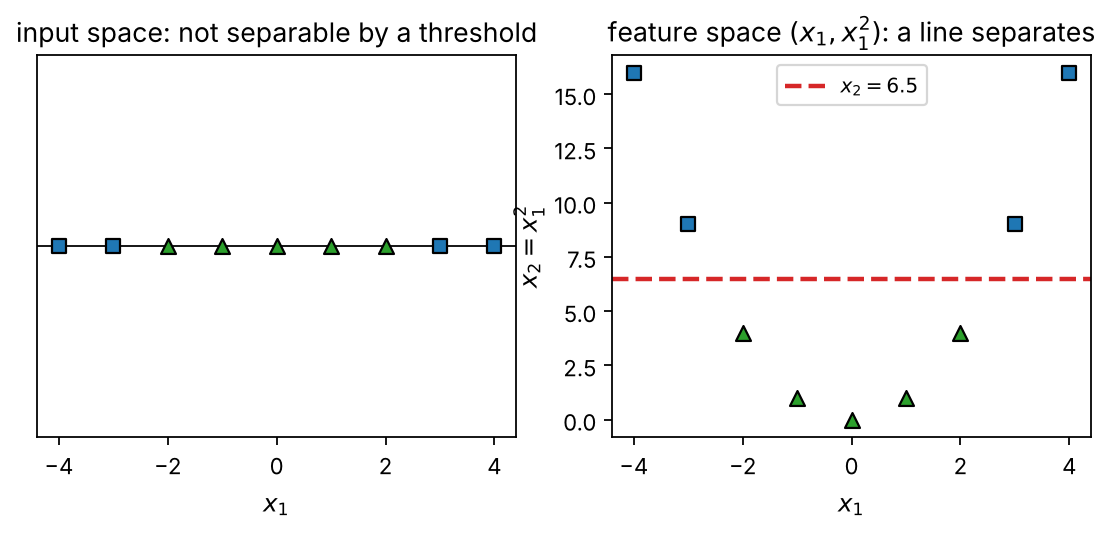

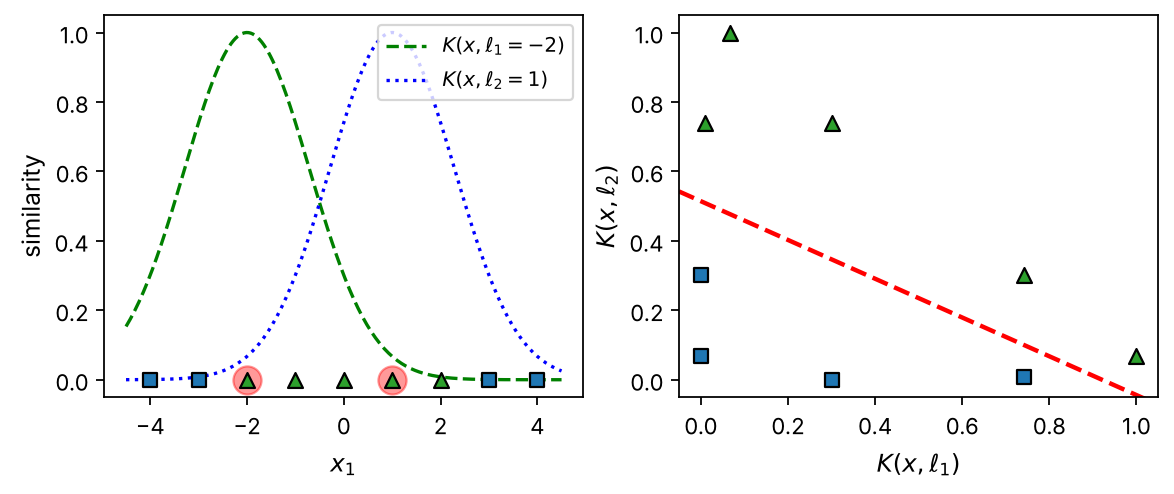

In [7]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter2/kernels.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


hard margin: w = (1.2494, -0.0909), b = -0.0248, margin 1/||w|| = 0.7983, 3 support vectors, 57 SMO updates


soft margin, overlapping blobs:
  C =   0.05: margin 1.092, 28 support vectors, 26 margin violations, training accuracy 0.95
  C =   1.00: margin 0.561, 11 support vectors,  9 margin violations, training accuracy 0.97


  C = 100.00: margin 0.254,  7 support vectors,  6 margin violations, training accuracy 0.97


two moons (standardized), C = 5:


  linear           training accuracy 0.88, 34 support vectors


  poly(d=3,r=1)    training accuracy 0.98, 12 support vectors


  rbf(gamma=0.5)   training accuracy 0.96, 20 support vectors


      dual objective: SMO 56.300498, scikit-learn 56.300491


  rbf(gamma=5)     training accuracy 0.98, 43 support vectors
      dual objective: SMO 28.406400, scikit-learn 28.406389


figures hardmargin, softmargin and moons written


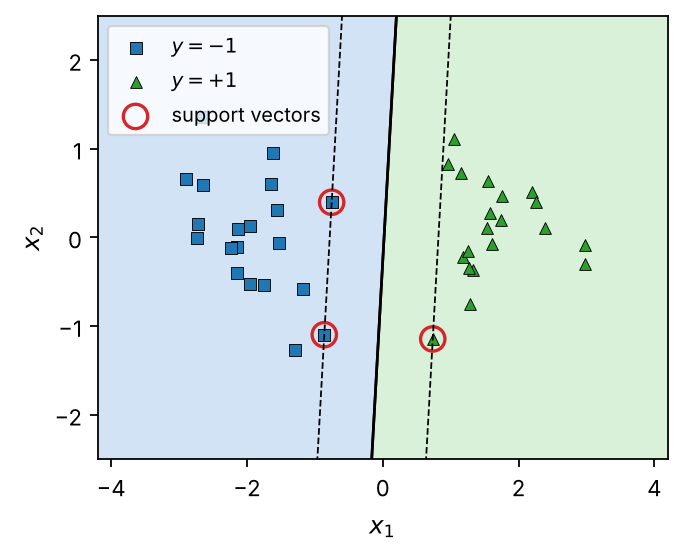

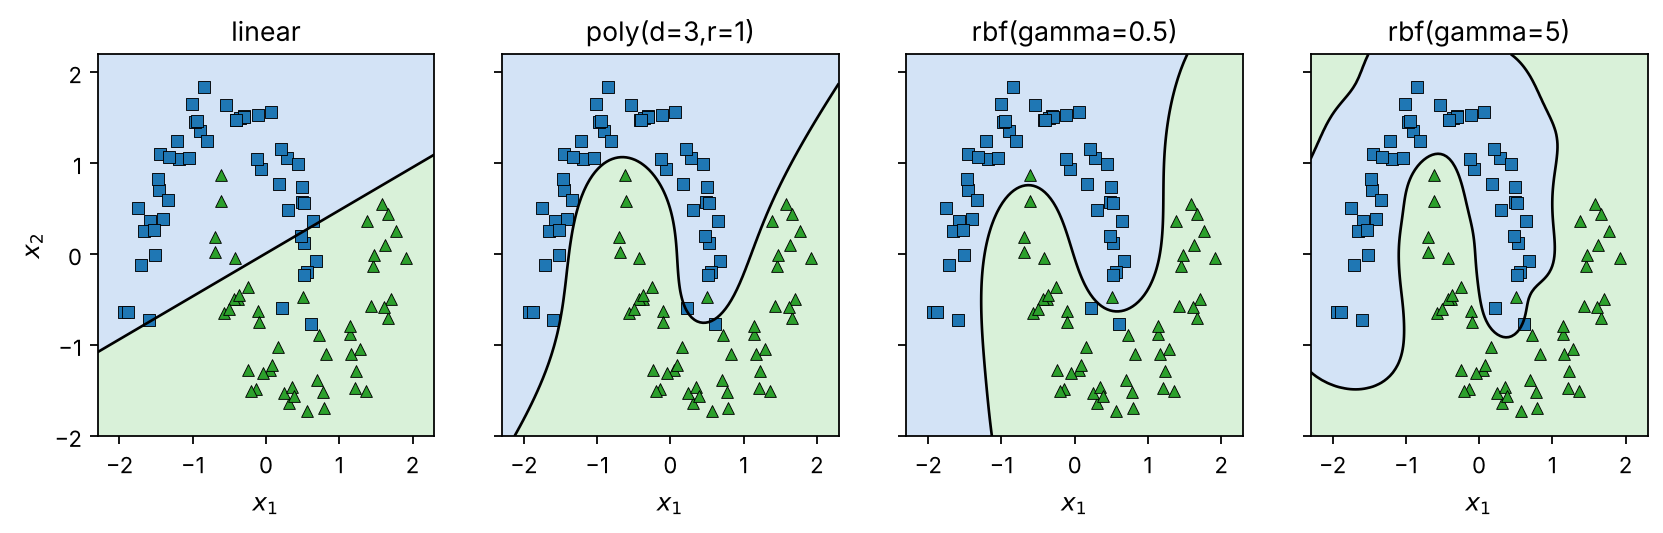

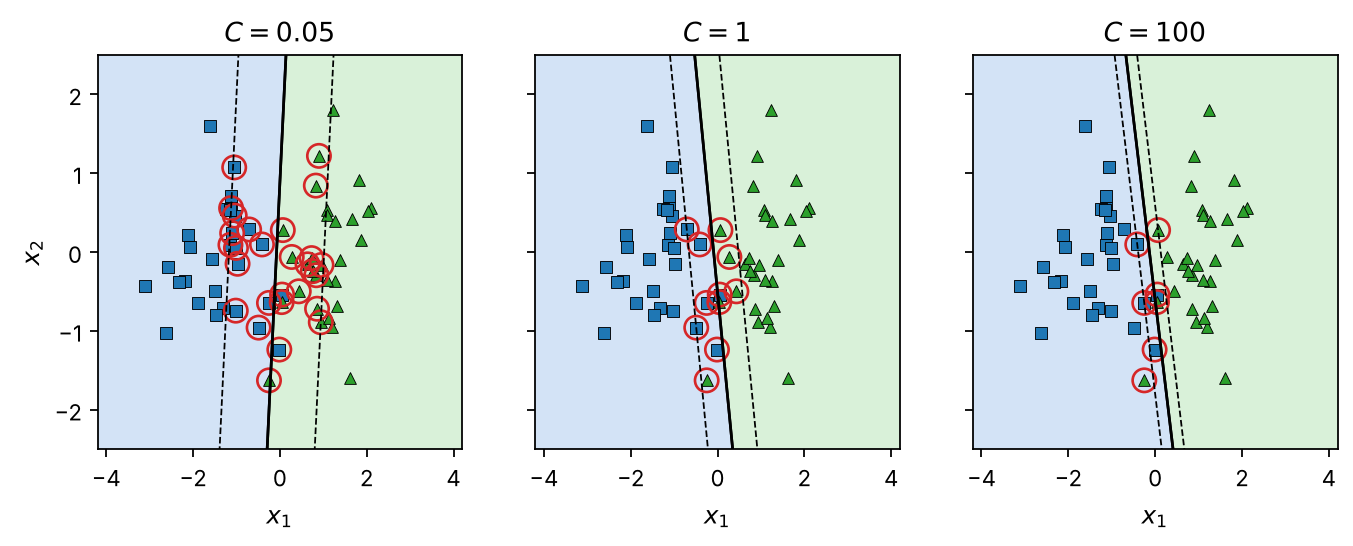

In [8]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter2/svm.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


In [9]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter2/feature_maps.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


angle encoding: K = 0.701933 = prod_i cos^2((x_i - x'_i)/2)
amplitude encoding: K = (x.x')^2 / (|x|^2 |x'|^2)
ZZ feature map agrees with exp(i sum phi Z) H^{(x)2} up to a global phase
fidelity 0.156984: adjoint test P(00) = 0.156984, SWAP test P(anc=0) = 0.578492 = (1+F)/2
1000 shots of the adjoint test: {'00': 164, '01': 33, '10': 798, '11': 5} -> K ~ 0.164
Gram matrix of the ZZ kernel: symmetric, unit diagonal, PSD; quantum-kernel checks passed


Table 2-qsvmdata: training / test accuracy, C = 1.0, 70/30 split
data set                                    linear          rbf(gamma=1)              angle(Y)   angle(Y,reps=2,ent)            zz(reps=2)  zz(reps=2,alpha=0.5)
                                        train/test            train/test            train/test            train/test            train/test            train/test


moons                              0.89/0.83             0.96/0.97             0.89/0.77             0.89/0.83             0.77/0.83             0.94/0.90      


circles                            0.67/0.37             1.00/1.00             1.00/1.00             0.99/1.00             0.80/0.73             0.96/0.97      


xor                                0.81/0.60             1.00/1.00             1.00/1.00             0.97/0.90             0.81/0.83             1.00/1.00      


iris (versicolor/virginica)        0.96/0.90             0.97/0.90             0.96/0.90             0.97/0.90             0.83/0.70             0.93/0.87      


...

  swap         100 shots: max|dK| 0.3704  rms 0.0918  min eig -1.125  test acc 0.93


  swap        1000 shots: max|dK| 0.1258  rms 0.0299  min eig -0.335  test acc 1.00


  swap       10000 shots: max|dK| 0.0378  rms 0.0094  min eig -0.104  test acc 1.00


  swap      100000 shots: max|dK| 0.0120  rms 0.0029  min eig -0.036  test acc 1.00


figures qsvmmoons, havlicek and shots written


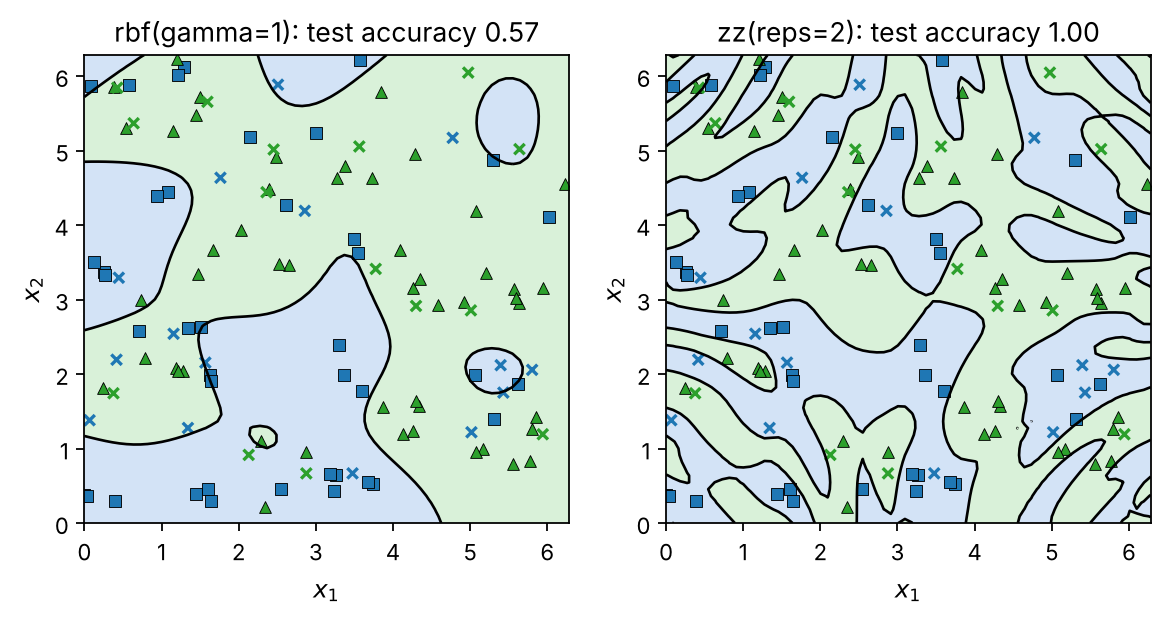

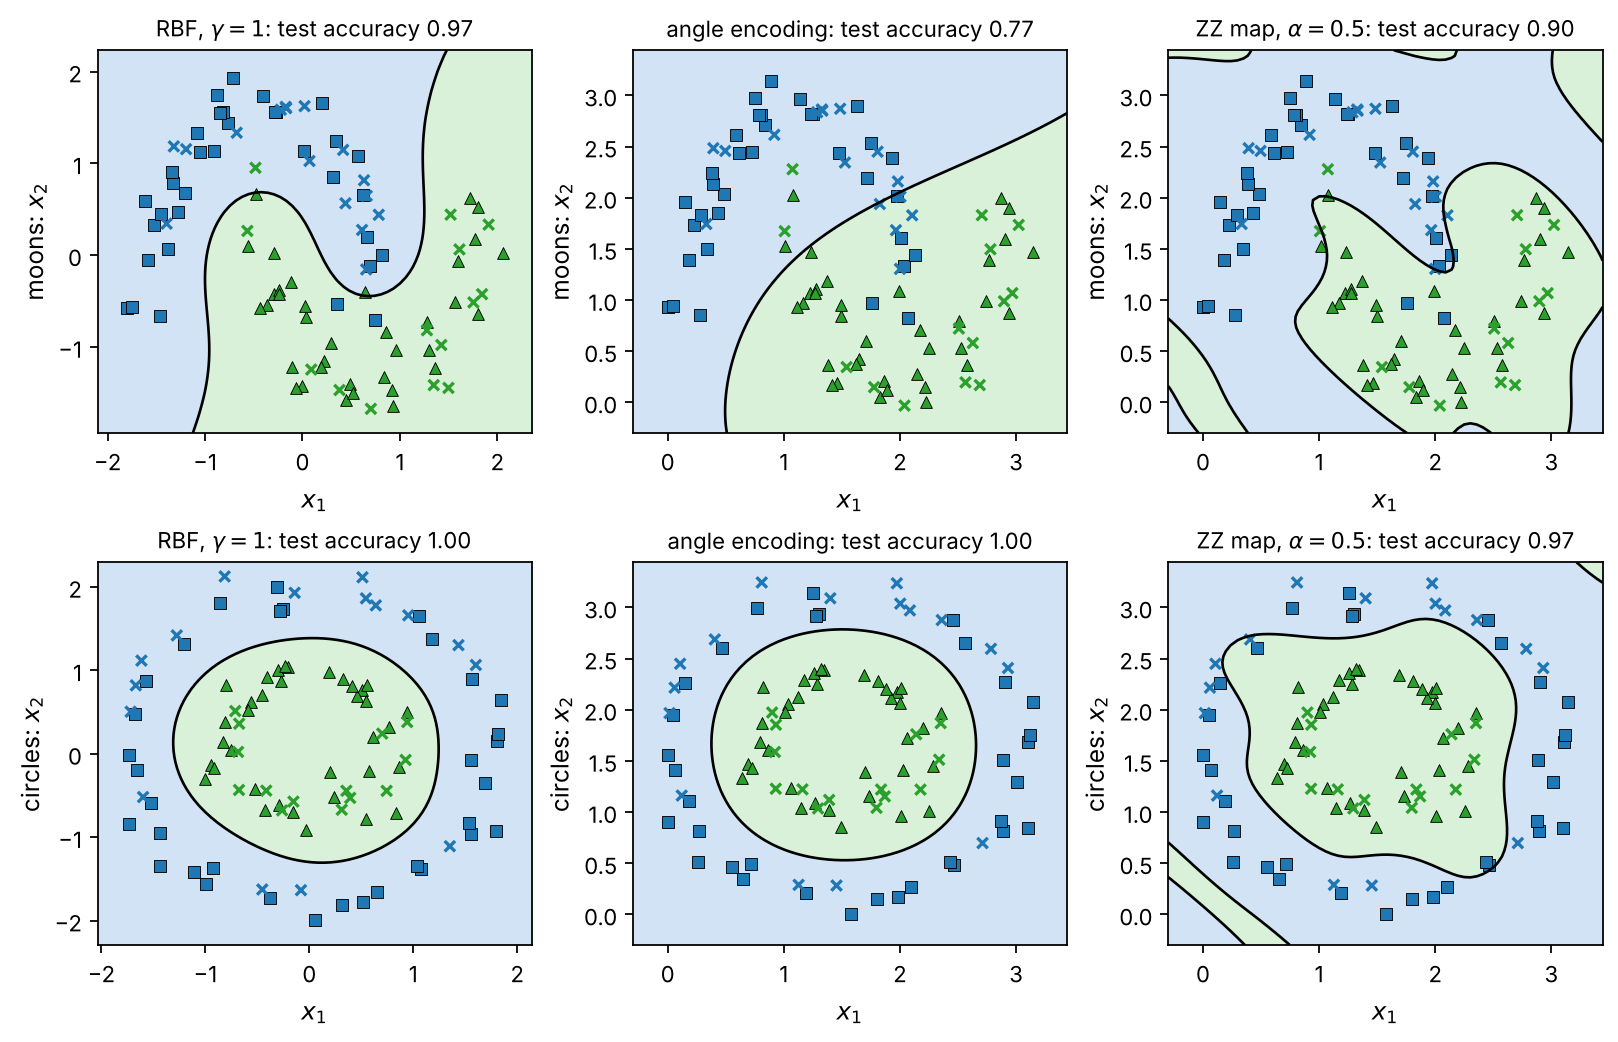

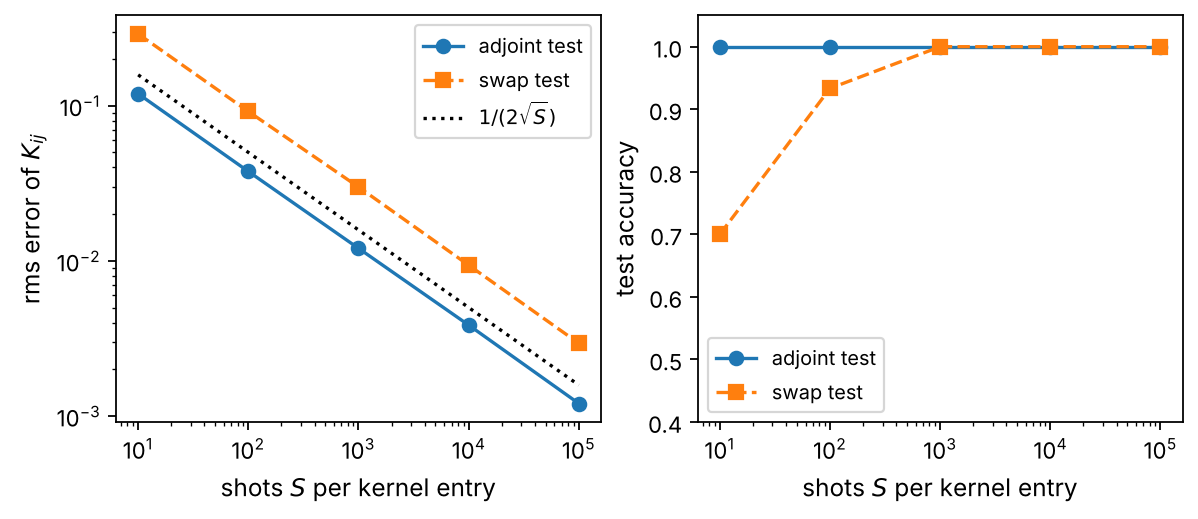

In [10]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter2/qsvm.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


parameter-shift gradient of the alignment agrees with finite differences (max difference 9.3e-12)


step  0: alignment 0.1395  train/test accuracy 0.80/0.67


step  5: alignment 0.2127  train/test accuracy 0.91/0.90


step 10: alignment 0.2331  train/test accuracy 0.94/0.97


step 15: alignment 0.2460  train/test accuracy 0.97/0.97


...

step 25: alignment 0.2882  train/test accuracy 0.94/0.97


step 30: alignment 0.3208  train/test accuracy 0.99/0.97


step 35: alignment 0.3537  train/test accuracy 0.97/0.97


step 40: alignment 0.3702  train/test accuracy 0.97/1.00
input weights after training: [2.928 1.748 3.407 2.291]


figure alignment written


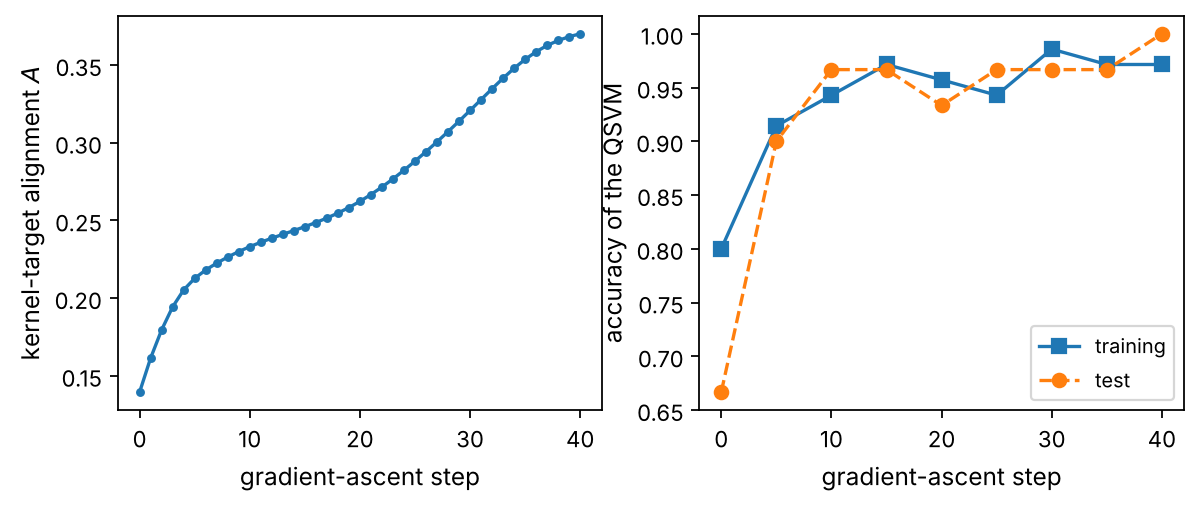

In [11]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter2/kernel_alignment.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))
